<a href="https://colab.research.google.com/github/sreevathsan-v/idse-india-healthtech-opportunity/blob/main/IDSE_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Where Should a Healthtech Startup Launch First?
## A district-level opportunity analysis of India using NFHS-4 and NFHS-5

**Course:** IDSE, Data Science Project (Part A) | **Team Members:** 1) Fedal Castro Jayakumar Gandhimathi (EC24B1052), 2) Sreevathsan V (EC24B1080) and 3) Kabilaash R B (EC24B1082) | **Date:** November 2026

**Summary.** A telemedicine or primary-care startup cannot serve all of India at once, so we have to choose where to pilot first. For 707 districts we predict what share of births *should* happen in a health facility, given education, housing and infrastructure, and compare that with what actually happens. Districts that fall well short, and that also have high nutrition-related health need, form our shortlist. A state-level digital-readiness check then suggests whether each district suits pure telemedicine or an assisted model (a local health worker plus a remote doctor).

**Pipeline**

| Step | What happens | Rubric row |
|---|---|---|
| 1 | Problem definition and objectives | Problem and data |
| 2 | Data collection and description | Problem and data |
| 3 | Data cleaning and preprocessing | Data preparation and EDA |
| 4 | Exploratory data analysis | Data preparation and EDA |
| 5 | Feature engineering | Data preparation and EDA |
| 6 | Inferential statistics | Modelling / analysis |
| 7 | Model building | Modelling / analysis |
| 8 | Evaluation and overfitting analysis | Evaluation and interpretation |
| 9 | Opportunity ranking, conclusions, limitations | Evaluation, Report |

**Reproducibility:** fixed seed (`RANDOM_STATE = 42`), versions in `requirements.txt`, run with *Runtime, Restart session and run all*. Data are downloaded at run time from public GitHub copies of the official IIPS factsheets.

## Step 1: Problem Definition and Objectives

### 1.1 Business context
Healthtech startups in India (telemedicine, primary-care and chronic-care services) have limited money and must choose where to launch first. Launching where care already exists wastes effort. Launching where people cannot connect to the service fails. The best first districts combine a large access gap, high need, and enough digital readiness.

### 1.2 Problem statement
**Which districts have much lower access to institutional healthcare than their socioeconomic conditions predict, and also high health need, so that they are the best candidates for a first pilot?**

### 1.3 Measurable goals
1. Predict district-level **institutional births (%)** from socioeconomic and infrastructure indicators, with a cross-validated error clearly below a mean-predictor baseline, and with no leakage between states.
2. Flag districts whose **actual access is below the predicted level by more than our model's typical error**.
3. Rank those districts by shortfall multiplied by nutrition burden.
4. Check which delivery model (pure telemedicine or assisted) suits each shortlisted district, using state-level internet use.

### 1.4 Research questions and hypotheses
| Question | H0 | H1 |
|---|---|---|
| Do districts with more educated women have higher institutional births? | Equal means | Different means |
| Does clean cooking fuel (a wealth proxy) go with higher institutional births? | Equal means | Different means |
| Is education level associated with access level? | Independent | Associated |

### 1.5 Idea in plain words
We predict what access a district *should* have, compare with what it *does* have, and treat the shortfall as our opportunity. Need (nutrition burden) is kept out of the model on purpose and is used only to rank, so the logic is not circular.

### 1.6 Success criteria
- Grouped-CV RMSE clearly below the baseline's 10.67 (computed in Step 7).
- All preprocessing fitted on training data only.
- A shortlist that survives a stricter threshold.
- Every cleaning and modelling decision explained.

In [42]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs('figures', exist_ok=True)   # figures for the README are saved here

In [43]:
![ -d NFHS ] || git clone https://github.com/SaiSiddhardhaKalla/NFHS.git
!ls NFHS

assets		   India.csv	 Procfile	   runtime.txt
Districts.geojson  nfhs_dash.py  README.md	   _states
India_Change.csv   pdfs		 requirements.txt


In [41]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/idse_project
!cp nfhs5_wide.csv nfhs4_wide.csv /content/drive/MyDrive/idse_project/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 2: Data Collection and Description

### 2.1 Source and justification
- **Source:** National Family Health Survey (NFHS), run by the International Institute for Population Sciences (IIPS) for the Ministry of Health and Family Welfare. NFHS-5 is 2019-21 and NFHS-4 is 2015-16.
- **Why NFHS:** a large government survey that gives district-level estimates for 100+ health, nutrition and household indicators, with the same indicators in both rounds so changes over time can be checked.
- **Format:** IIPS publishes district factsheets as PDFs. We use a public GitHub repository (`SaiSiddhardhaKalla/NFHS`) that converted them to one CSV and matched districts to 2011 Census codes. Automated conversion can introduce errors, so we validate it in Step 3.
- **Digital readiness (Step 9):** state-level figures from the NFHS-5 state factsheets (repository `pratapvardhan/NFHS-5`).
- **Not used:** Census population, facility counts and doctors per capita. They were not merged, so our study cannot size the market. This is listed under limitations.

### 2.2 Loading the data
We clone the repository into our notebook session. `India.csv` has one row per district and indicator ("long" format), with the NFHS-5 and NFHS-4 values side by side.

In [44]:
import pandas as pd

df = pd.read_csv('NFHS/India.csv',low_memory = False)
print(df.shape)
print(df.columns.tolist())
display(df.head())
print(df.isna().sum().sort_values(ascending=False).head(20))

(73632, 9)
['State', 'ST_CEN_CD', 'District', 'DISTRICT', 'DT_CEN_CD', 'Category', 'Indicator', 'NFHS 5', 'NFHS 4']


,State,ST_CEN_CD,District,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Female population age 6 years and above who ever attende...,78.0,77.2
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Population below age 15 years (%),23.0,25.4
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,"Sex ratio of the total population (females per 1,000 males)",973.0,957.0
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Sex ratio at birth for children born in the last five ye...,927.0,1060.0
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Children under age 5 years whose birth was registered wi...,98.0,99.3


DT_CEN_CD    6760
DISTRICT     6656
State           0
District        0
ST_CEN_CD       0
Category        0
Indicator       0
NFHS 5          0
NFHS 4          0
dtype: int64


### 2.3 Dataset overview
Before cleaning, check the structure: number of states, districts and indicators, duplicate district-indicator pairs, zero values and indicator categories.

In [45]:
import pandas as pd, numpy as np

df = pd.read_csv('NFHS/India.csv', low_memory=False)

# 1. Structure
print("States:", df['State'].nunique())
print("Districts:", df.groupby(['State', 'District']).ngroups)
print("Indicators:", df['Indicator'].nunique())
print("Duplicate district-indicator rows:", df.duplicated(['State', 'District', 'Indicator']).sum())

# 2. Zeros (possible hidden missing values)
print("\nZeros in NFHS 5:", (df['NFHS 5'] == 0).sum(), "| in NFHS 4:", (df['NFHS 4'] == 0).sum())
print(df[df['NFHS 5'] == 0]['Indicator'].value_counts().head(10))

# 3. Categories
print("\n", df.drop_duplicates('Indicator')['Category'].value_counts())

# 4. All indicator names (numbered)
for i, ind in enumerate(df['Indicator'].unique()):
    print(i, ind)

States: 38
Districts: 709
Indicators: 105
Duplicate district-indicator rows: 105

Zeros in NFHS 5: 5980 | in NFHS 4: 32259
Indicator
Nonbreastfeeding children age 6-23 months receiving an adequate diet (%)                                                        649
Children age 6-8 months receiving solid or semisolid food and breastmilk (%)                                                    644
Children born at home who were taken to a health facility for a checkup within 24 hours of birth (%)                            502
Children with diarrhoea in the 2 weeks preceding the survey who received oral rehydration salts (ORS) (%)                       493
Children with diarrhoea in the 2 weeks preceding the survey taken to a health facility or health provider (%)                   493
Children with diarrhoea in the 2 weeks preceding the survey who received zinc (%)                                               493
Male sterilization (%)                                                     

**Observations**
- The raw file has 73,632 rows and 9 columns, in long format: one row per district and indicator.
- It has 38 state labels, 709 district-state groups and 105 indicators in 19 categories (before cleaning).
- 210 rows are duplicated district-indicator pairs. Step 3 shows they come from two labelling problems in the source file.
- There are 5,980 zeros in NFHS-5 and 32,259 in NFHS-4. Many are not real zeros but suppressed or never-collected values stored as 0, so zeros cannot be taken at face value.
- Some indicator names contain typos (for example "age 2024" for 20-24, and "MaleBlood sugar"), so cleaning of names is needed.

### 2.4 Data dictionary: variables used

**Target (what the model predicts)**

| Short name | Indicator |
|---|---|
| `inst_births` | Institutional births (%) |

**Model features (socioeconomic and infrastructure)**

| Short name | Indicator |
|---|---|
| `fem_school` | Female population age 6+ who ever attended school (%) |
| `women_10yr` | Women with 10 or more years of schooling (%) |
| `pop_u15` | Population below age 15 (%) |
| `sex_ratio` | Females per 1,000 males |
| `birth_reg` | Children under 5 whose birth was registered (%) |
| `electricity` | Population in households with electricity (%) |
| `water` | Population in households with an improved drinking-water source (%) |
| `sanitation` | Population in households using improved sanitation (%) |
| `clean_fuel` | Households using clean cooking fuel (%) |
| `iodized_salt` | Households using iodized salt (%) |
| `insurance` | Households with any member covered by health insurance (%) |
| `child_marriage` | Women age 20-24 married before 18 (%) |
| `teen_mothers` | Women age 15-19 already mothers or pregnant (%) |
| `menstrual_hygiene` | Women age 15-24 using hygienic menstrual protection (%) |

**Burden indicators (used only for ranking, never as model inputs)**

| Short name | Indicator |
|---|---|
| `anaemia_women` | All women age 15-49 who are anaemic (%) |
| `stunting` | Children under 5 who are stunted (%) |
| `sugar_f`, `sugar_m` | Women / men with high blood sugar or on medication (%) |
| `bp_f`, `bp_m` | Women / men with elevated blood pressure or on medication (%) |

**Deliberately excluded.** Antenatal care, postnatal care, delivery care and vaccination indicators measure the same behaviour as the target, so using them as inputs would be leakage.

In [46]:
import pandas as pd, numpy as np, re

df = pd.read_csv('NFHS/India.csv', low_memory=False)

# --- 1. Find the duplicated district ---
dups = df[df.duplicated(['State', 'District', 'Indicator'], keep=False)]
print("Duplicated rows:", len(dups))
print(dups.groupby(['State', 'District']).size())

# --- 2. Clean indicator names ---
def clean_ind(s):
    s = str(s).replace('MaleBlood', 'Male Blood')
    return re.sub(r'\s+', ' ', s).strip()

df['Indicator'] = df['Indicator'].map(clean_ind)
print("\nIndicators after name cleaning:", df['Indicator'].nunique())

# --- 3. Do the merged blood-sugar rows agree? ---
bs = df[df['Indicator'].str.startswith('Male Blood sugar level high (141-160')]
print(bs.groupby(['State', 'District']).size().value_counts())

# --- 4. Zero rate per indicator, both rounds ---
for col in ['NFHS 5', 'NFHS 4']:
    z = (df[col] == 0).groupby(df['Indicator']).mean().sort_values(ascending=False)
    print(f"\n{col}: indicators with >95% zeros: {(z > 0.95).sum()}")
    print(z.head(25).round(2))

# --- 5. Zero rate per district ---
dz = df.assign(z4=(df['NFHS 4'] == 0), z5=(df['NFHS 5'] == 0)) \
       .groupby(['State', 'District'])[['z4', 'z5']].mean()
print("\nDistricts with >90% zeros in NFHS-4:", (dz['z4'] > 0.9).sum())
print("Districts with >90% zeros in NFHS-5:", (dz['z5'] > 0.9).sum())

# --- 6. Our target ---
t = df[df['Indicator'] == 'Institutional births (%)']
print("\nTarget rows:", len(t),
      "| zeros NFHS-5:", (t['NFHS 5'] == 0).sum(),
      "| zeros NFHS-4:", (t['NFHS 4'] == 0).sum())

Duplicated rows: 210
State          District 
Chhattisgarh   Surajpur       2
Jharkhand      Sahibganj    208
dtype: int64

Indicators after name cleaning: 104
1    706
2      1
Name: count, dtype: int64

NFHS 5: indicators with >95% zeros: 0
Indicator
Nonbreastfeeding children age 6-23 months receiving an adequate diet (%)                                                        0.92
Children age 6-8 months receiving solid or semisolid food and breastmilk (%)                                                    0.91
Children born at home who were taken to a health facility for a checkup within 24 hours of birth (%)                            0.71
Children with diarrhoea in the 2 weeks preceding the survey who received zinc (%)                                               0.70
Children with diarrhoea in the 2 weeks preceding the survey taken to a health facility or health provider (%)                   0.70
Children with diarrhoea in the 2 weeks preceding the survey who received oral rehy

## Step 3: Data Cleaning and Preprocessing

The raw file was produced by converting PDFs automatically, so I validated it before using it. Every rule below has a reason.

### 3.1 Reshaping long to wide
The model needs one row per district and one column per indicator, so the table is pivoted. Only the target, features and burden indicators are kept.

### 3.2 Names and types
Indicator names are stripped of stray spaces and one typo (`MaleBlood`), which had made one indicator appear twice (105 to 104 indicators). Values are converted to numbers.

### 3.3 Hidden missing values (zeros)
| Rule | Reason |
|---|---|
| Districts with more than 90% zeros in NFHS-5 are dropped | A profile of almost all zeros is a placeholder or a parsing failure, not a real district |
| For modelled variables, 0 is treated as missing | A whole district with 0% electricity or 0% institutional births is implausible |
| Zeros in other indicators are left alone | Some are real (for example male sterilisation near 0%), and we do not model them |

### 3.4 Missing values
Missing values are rare (see output). They are **not** filled here. They are filled later with the training-set median inside the model pipeline, so no information leaks from test data. Rows missing the target would be dropped, since a target cannot be imputed; there are none.

### 3.5 Duplicates and labelling errors
Validation found two problems in the source file:
- **Sahibganj appeared twice with different numbers.** The second block carries the code `Saraikela-kharsawan_24` in the `DISTRICT` column, but its district name and census code were copied from Sahibganj. It is a mislabelled Saraikela-Kharsawan, so it is relabelled, not dropped. Jharkhand then has 24 districts.
- **Surajpur had one indicator (men's alcohol use) with two conflicting values.** I cannot tell which is right, so both rows are dropped. The indicator is not used in the model.

In [47]:
import pandas as pd, numpy as np, re
RANDOM_STATE = 42

# ---------- 2.2 Load ----------
raw = pd.read_csv('NFHS/India.csv', low_memory=False)
print("Raw shape:", raw.shape)

# ---------- 3.2 Clean names ----------
def clean_ind(s):
    s = str(s).replace('MaleBlood', 'Male Blood')
    return re.sub(r'\s+', ' ', s).strip()

raw['Indicator'] = raw['Indicator'].map(clean_ind)
raw['State'] = raw['State'].str.strip()
raw['District'] = raw['District'].str.strip()

# ---------- 3.5 Fix source parsing errors ----------
# (a) Saraikela-Kharsawan was mislabelled as Sahibganj in the source CSV
fix = raw['DISTRICT'] == 'Saraikela-kharsawan_24'
print("Rows relabelled to Saraikela-Kharsawan:", fix.sum())   # expect 104
raw.loc[fix, 'District'] = 'Saraikela-Kharsawan'
raw.loc[fix, 'DT_CEN_CD'] = np.nan   # code copied from Sahibganj, so wrong; re-match later

# (b) Surajpur: one indicator has two conflicting values, so drop both (not used in the model)
alc = (raw['District'] == 'Surajpur') & \
      raw['Indicator'].str.startswith('Men age 15 years and above who consume alcohol')
print("Surajpur alcohol rows dropped:", alc.sum())            # expect 2
raw = raw[~alc]

# ---------- 3.5 Duplicates ----------
key = ['State', 'District', 'Indicator']
d = raw[raw.duplicated(key, keep=False)]
print("Duplicate rows:", len(d))
print("Max distinct values within a duplicate group (1 = identical):")
print(d.groupby(key)[['NFHS 5', 'NFHS 4']].nunique().max())
raw = raw.drop_duplicates(key, keep='first')
print("Shape after dropping duplicates:", raw.shape)

# ---------- 3.3 Drop parse-failure districts (>90% zeros in NFHS-5) ----------
z5 = (raw['NFHS 5'] == 0).groupby([raw['State'], raw['District']]).mean()
bad = z5[z5 > 0.9].index
print("Districts dropped (all-zero NFHS-5):", list(bad))
raw = raw[~raw.set_index(['State', 'District']).index.isin(bad)]

# ---------- 5.x Variables we will use (short name -> indicator) ----------
TARGET = {'inst_births': 'Institutional births (%)'}
FEATURES = {
    'fem_school': 'Female population age 6 years and above who ever attended school (%)',
    'women_10yr': 'Women with 10 or more years of schooling (%)',
    'pop_u15': 'Population below age 15 years (%)',
    'sex_ratio': 'Sex ratio of the total population (females per 1,000 males)',
    'birth_reg': 'Children under age 5 years whose birth was registered with the civil authority (%)',
    'electricity': 'Population living in households with electricity (%)',
    'water': 'Population living in households with an improved drinkingwater source (%)',
    'sanitation': 'Population living in households that use an improved sanitation facility (%)',
    'clean_fuel': 'Households using clean fuel for cooking (%)',
    'iodized_salt': 'Households using iodized salt (%)',
    'insurance': 'Households with any usual member covered under a health insurance/financing scheme (%)',
    'child_marriage': 'Women age 2024 years married before age 18 years (%)',
    'teen_mothers': 'Women age 15-19 years who were already mothers or pregnant at the time of the survey (%)',
    'menstrual_hygiene': 'Women age 15-24 years who use hygienic methods of protection during their menstrual period (%)',
}
BURDEN = {
    'anaemia_women': 'All women age 15-49 years who are anaemic (%)',
    'stunting': 'Children under 5 years who are stunted (height for age) (%)',
    'sugar_f': 'Female Blood sugar level high or very high (>140 mg/dl) or taking medicine to control blood sugar level (%)',
    'sugar_m': 'Male Blood sugar level high or very high (>140 mg/dl) or taking medicine to control blood sugar level (%)',
    'bp_f': 'Female Elevated blood pressure or taking medicine to control blood pressure (%)',
    'bp_m': 'Male Elevated blood pressure or taking medicine to control blood pressure (%)',
}
ALL = {**TARGET, **FEATURES, **BURDEN}

notfound = [v for v in ALL.values() if v not in set(raw['Indicator'])]
print("\nIndicator names NOT found (must be empty):", notfound)

# ---------- 3.1 Reshape long -> wide ----------
sub = raw[raw['Indicator'].isin(ALL.values())].copy()
sub['var'] = sub['Indicator'].map({v: k for k, v in ALL.items()})
for c in ['NFHS 5', 'NFHS 4']:
    sub[c] = pd.to_numeric(sub[c], errors='coerce')

# ---------- 3.3/3.4 Zero -> missing for these variables ----------
print("\nZeros converted to NaN (NFHS-5), by variable:")
print((sub['NFHS 5'] == 0).groupby(sub['var']).sum().sort_values(ascending=False))
for c in ['NFHS 5', 'NFHS 4']:
    sub.loc[sub[c] == 0, c] = np.nan

w5 = sub.pivot_table(index=['State', 'District'], columns='var', values='NFHS 5', aggfunc='first')
w4 = sub.pivot_table(index=['State', 'District'], columns='var', values='NFHS 4', aggfunc='first')
w5 = w5.reindex(columns=list(ALL))
w4 = w4.reindex(index=w5.index, columns=list(ALL))

# Census codes for later merge
cen = raw.groupby(['State', 'District'])[['ST_CEN_CD', 'DT_CEN_CD']].first()
nfhs5 = w5.join(cen).reset_index()
nfhs4 = w4.join(cen).reset_index()

# ---------- Checks ----------
print("\nNFHS-5 wide shape:", nfhs5.shape)
print("\nMissing values per variable (NFHS-5):")
print(w5.isna().sum().sort_values(ascending=False))
print("\nNFHS-4 coverage (share of districts with a value):")
print(w4.notna().mean().round(2).sort_values())
print("\nDistricts with NFHS-4 target:", w4['inst_births'].notna().sum())
print("Districts missing NFHS-5 target:", w5['inst_births'].isna().sum())

# Save (Colab deletes local files at session end, so copy these to Drive)
nfhs5.to_csv('nfhs5_wide.csv', index=False)
nfhs4.to_csv('nfhs4_wide.csv', index=False)

Raw shape: (73632, 9)
Rows relabelled to Saraikela-Kharsawan: 104
Surajpur alcohol rows dropped: 2
Duplicate rows: 0
Max distinct values within a duplicate group (1 = identical):
NFHS 5   NaN
NFHS 4   NaN
dtype: float64
Shape after dropping duplicates: (73630, 9)
Districts dropped (all-zero NFHS-5): [('Jammu & Kashmir', 'Data Not Available')]

Indicator names NOT found (must be empty): []

Zeros converted to NaN (NFHS-5), by variable:
var
teen_mothers         17
bp_m                  1
child_marriage        1
bp_f                  0
anaemia_women         0
birth_reg             0
clean_fuel            0
fem_school            0
electricity           0
insurance             0
iodized_salt          0
menstrual_hygiene     0
inst_births           0
pop_u15               0
sanitation            0
stunting              0
sex_ratio             0
sugar_f               0
sugar_m               0
water                 0
women_10yr            0
Name: NFHS 5, dtype: int64

NFHS-5 wide shape: (707, 

**Observations (3.1 to 3.5)**
- 104 rows were relabelled to Saraikela-Kharsawan and 2 Surajpur rows were dropped, leaving 73,630 rows with 0 duplicates.
- One placeholder district (Jammu & Kashmir, "Data Not Available") was all zeros and was dropped.
- All 21 selected indicator names were found in the data (the check printed an empty list).
- Zeros converted to missing in NFHS-5: `teen_mothers` 17, `child_marriage` 1, `bp_m` 1. No other selected variable had zeros.
- The wide table has **707 districts**. Missing values are rare (`teen_mothers` 17, `child_marriage` 1, `bp_m` 1 at this stage).
- NFHS-4 covers about 81% of districts for the 17 model variables and 0% for blood sugar and blood pressure, which NFHS-4 did not record at district level. 575 districts have an NFHS-4 target value.

### Check: did the relabelling work?
Jharkhand should have 24 districts, and Saraikela-Kharsawan and Sahibganj should now have different values.

In [48]:
print(nfhs5[nfhs5['State'] == 'Jharkhand'].shape[0], "Jharkhand districts (expect 24)")
print(nfhs5[nfhs5['District'] == 'Saraikela-Kharsawan'][['inst_births', 'electricity', 'clean_fuel']])
print(nfhs5[nfhs5['District'] == 'Sahibganj'][['inst_births', 'electricity', 'clean_fuel']])

24 Jharkhand districts (expect 24)
     inst_births  electricity  clean_fuel
249         81.8         93.5        31.5
     inst_births  electricity  clean_fuel
248         64.7         91.6        17.4


**Observation.** Jharkhand has 24 districts. Saraikela-Kharsawan (institutional births 81.8%, electricity 93.5%, clean fuel 31.5%) and Sahibganj (64.7%, 91.6%, 17.4%) now differ, which confirms they were two separate districts.

### 3.6 Outlier detection and handling

**Method.** (a) A validity check: percentages must lie between 0 and 100. (b) The IQR rule (values beyond 1.5 times the interquartile range). (c) Boxplots, and a look at which districts are extreme.

**Decision rule.** Remove or correct a value only if it is impossible or clearly a data-entry or parsing error. Keep extreme but plausible survey estimates. Reason: they are real districts, and the poorly served districts are exactly what this project looks for. Deleting them would delete the answer.

**Observations (3.6)**
- No impossible values: every percentage lies between 0 and 100.
- Electricity (62 flags), water (56), iodized salt (54) and birth registration (34) have the most IQR outliers. They are near 100% in most districts, so the "outliers" are the few lagging districts. This is a ceiling effect, not an error.
- The lowest institutional births are in Nagaland (Mon 21.4%, Phek 32.2%, Kiphire and Tuensang 34.8%) and Meghalaya (South West Khasi Hills and West Khasi Hills 41.7%). These are real, remote hill districts, so they are kept.
- Sex ratio runs from 755 (Daman) to 1,332 (Diu). Both are small districts, so sampling error is likely larger. They are kept.
- A few points look implausible rather than impossible. They are examined in the next cell.

### 3.6b Investigating suspicious values
Some boxplot points look implausible: `teen_mothers` near 80-92%, `child_marriage` above 55%, `menstrual_hygiene` below 20% and `iodized_salt` below 55%. I list the districts and compare them with NFHS-4 before deciding.

**Observations**
- Chandigarh and Lakshadweep show teen mothers 91.9% and 80.3%, child marriage 64.5% and 80.9%, and menstrual hygiene 9.7% and 1.3%. Typical districts are below 10% for teen mothers and mostly above 60% for menstrual hygiene. All three variables are off in the same two rows, while their other variables are plausible. This points to a systematic misreading of these two union-territory factsheets, not to real values.
- The Bihar and West Bengal child-marriage values of 55-58% (Lakhisarai, Supaul, Murshidabad, Paschim Medinipur, Purba Medinipur) are broadly consistent with NFHS-4 (for example Murshidabad 55.4% vs 53.5%), so they are treated as real.
- Koppal (Karnataka) has iodized salt at 47.9%. It is a single plausible value, so it is kept.
- **To do before submission:** open the Chandigarh and Lakshadweep PDFs in the source repository's `pdfs` folder and confirm the true values are low. Then state that confirmation here.

### 3.6c Correcting the parsing errors
Only the three misparsed variables for Chandigarh and Lakshadweep are set to missing, in both survey rounds. The rows are kept because their other 18 variables are plausible. The model pipeline fills the three gaps with training medians later. An `assert` stops the notebook if the fix does not apply.

**Observation.** After the fix, `teen_mothers` has 688 values, `child_marriage` 704 and `menstrual_hygiene` 705 (out of 707). The cleaned dataset is ready for exploration.

In [49]:
import matplotlib.pyplot as plt

df5 = nfhs5.copy()
TARGET_COL = 'inst_births'
FEAT_COLS = list(FEATURES)
BURDEN_COLS = list(BURDEN)
NUM_COLS = [TARGET_COL] + FEAT_COLS + BURDEN_COLS

# ---- 3.6a Validity check: percentages must lie in 0-100 ----
pct_cols = [c for c in NUM_COLS if c != 'sex_ratio']
bad = ((df5[pct_cols] < 0) | (df5[pct_cols] > 100)).sum().sum()
print("Impossible percentage values:", bad)
print("\nSex ratio summary (females per 1,000 males):")
print(df5['sex_ratio'].describe().round(1))

# ---- 3.6b IQR outlier detection ----
Q1, Q3 = df5[NUM_COLS].quantile(0.25), df5[NUM_COLS].quantile(0.75)
IQR = Q3 - Q1
lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
flags = (df5[NUM_COLS] < lo) | (df5[NUM_COLS] > hi)
print("\nIQR outliers per variable:")
print(flags.sum().sort_values(ascending=False))

# ---- 3.6c Who are the extreme districts? ----
print("\nLowest 8 districts on the target:")
print(df5.nsmallest(8, TARGET_COL)[['State', 'District', TARGET_COL]])
print("\nMost extreme sex ratios:")
print(df5.loc[[df5['sex_ratio'].idxmin(), df5['sex_ratio'].idxmax()],
              ['State', 'District', 'sex_ratio']])


Impossible percentage values: 0

Sex ratio summary (females per 1,000 males):
count     707.0
mean     1020.6
std        73.3
min       755.0
25%       969.0
50%      1013.0
75%      1065.5
max      1332.0
Name: sex_ratio, dtype: float64

IQR outliers per variable:
electricity          62
water                56
iodized_salt         54
birth_reg            34
teen_mothers         28
inst_births          24
anaemia_women        17
pop_u15              12
sugar_f              11
sex_ratio            10
sugar_m              10
bp_f                  8
bp_m                  8
child_marriage        7
women_10yr            6
stunting              3
menstrual_hygiene     2
sanitation            1
fem_school            0
insurance             0
clean_fuel            0
dtype: int64

Lowest 8 districts on the target:
         State                District  inst_births
429   Nagaland                     Mon         21.4
431   Nagaland                    Phek         32.2
425   Nagaland            

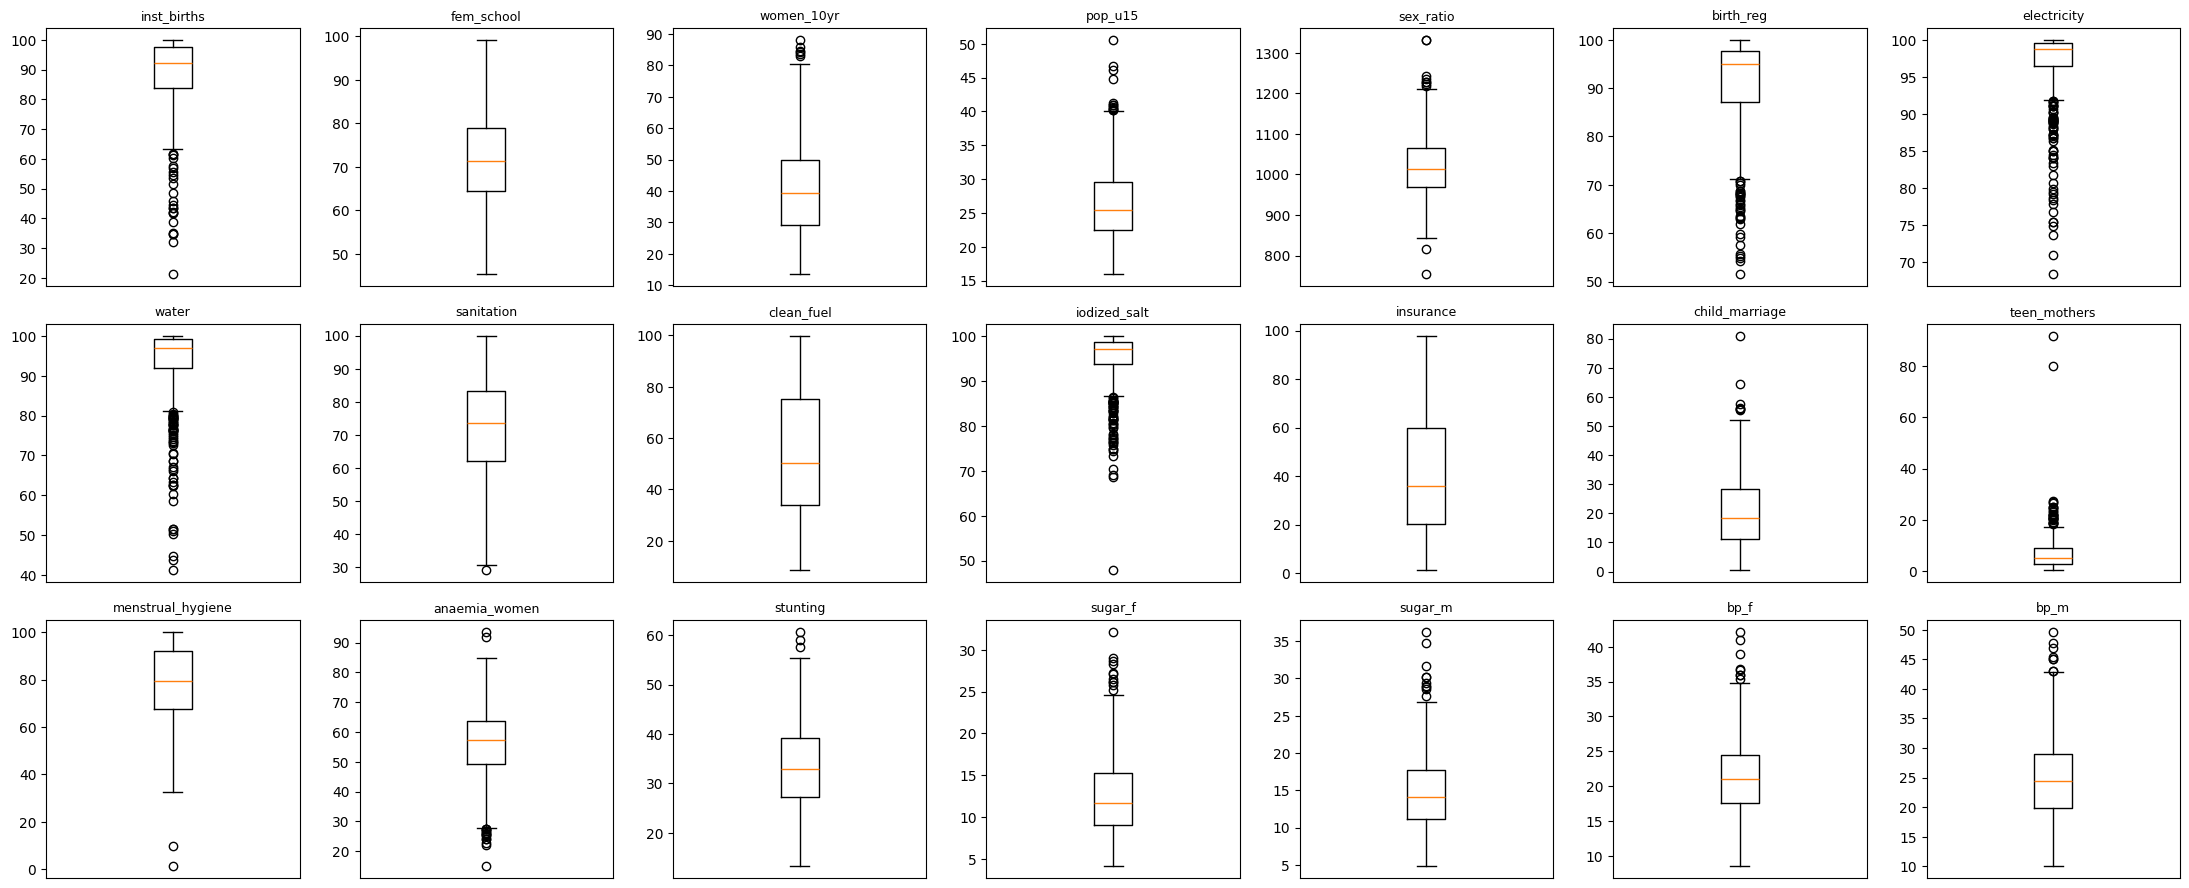

In [50]:

# ---- 3.6d Boxplots ----
fig, axes = plt.subplots(3, 7, figsize=(22, 9))
for ax, c in zip(axes.ravel(), NUM_COLS):
    ax.boxplot(df5[c].dropna(), vert=True)
    ax.set_title(c, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [51]:
checks = {
    'teen_mothers > 40':      df5['teen_mothers'] > 40,
    'child_marriage > 55':    df5['child_marriage'] > 55,
    'menstrual_hygiene < 20': df5['menstrual_hygiene'] < 20,
    'iodized_salt < 55':      df5['iodized_salt'] < 55,
}
for name, m in checks.items():
    print(f"\n--- {name} ---")
    print(df5.loc[m, ['State', 'District', 'teen_mothers', 'child_marriage',
                      'menstrual_hygiene', 'iodized_salt']])

# Compare with the same districts in NFHS-4 (a big jump suggests a parsing error)
cmp = df5[['State', 'District', 'teen_mothers', 'child_marriage']].merge(
    nfhs4[['State', 'District', 'teen_mothers', 'child_marriage']],
    on=['State', 'District'], suffixes=('_5', '_4'))
print("\nNFHS-5 vs NFHS-4 for the suspicious districts:")
print(cmp[(cmp['teen_mothers_5'] > 40) | (cmp['child_marriage_5'] > 55)])


--- teen_mothers > 40 ---
           State     District  teen_mothers  child_marriage  menstrual_hygiene  iodized_salt
107   Chandigarh   Chandigarh          91.9            64.5                9.7          96.8
297  Lakshadweep  Lakshadweep          80.3            80.9                1.3          96.7

--- child_marriage > 55 ---
           State           District  teen_mothers  child_marriage  menstrual_hygiene  iodized_salt
86         Bihar         Lakhisarai          13.0            56.1               64.9          84.2
105        Bihar             Supaul          17.0            55.9               55.4          94.3
107   Chandigarh         Chandigarh          91.9            64.5                9.7          96.8
297  Lakshadweep        Lakshadweep          80.3            80.9                1.3          96.7
697  West Bengal        Murshidabad          20.6            55.4               85.7          92.5
701  West Bengal  Paschim Medinipur          25.0            55.7      

In [52]:
# ---- 3.6e Parsing-error fix (Chandigarh, Lakshadweep) ----
suspect = df5['District'].isin(['Chandigarh', 'Lakshadweep'])
for c in ['teen_mothers', 'child_marriage', 'menstrual_hygiene']:
    df5.loc[suspect, c] = np.nan
    nfhs4.loc[nfhs4['District'].isin(['Chandigarh', 'Lakshadweep']), c] = np.nan

# Fails loudly if the fix did not apply
assert df5.loc[suspect, ['teen_mothers', 'child_marriage', 'menstrual_hygiene']].isna().all().all()
print("Counts after fix:", df5[['teen_mothers', 'child_marriage', 'menstrual_hygiene']].count().to_dict())

Counts after fix: {'teen_mothers': 688, 'child_marriage': 704, 'menstrual_hygiene': 705}


## Step 4: Exploratory Data Analysis

### 4.1 Descriptive statistics
Mean, median, spread, skewness and kurtosis for every variable, computed with pandas and NumPy.

In [53]:
# ---- 4.1 Descriptive statistics (pandas + NumPy) ----
desc = df5[NUM_COLS].describe().T
desc['median'] = df5[NUM_COLS].median()
desc['skew'] = df5[NUM_COLS].skew()
desc['kurtosis'] = df5[NUM_COLS].kurt()
desc['CV_%'] = 100 * desc['std'] / desc['mean']
display(desc.round(2))

t = df5[TARGET_COL].to_numpy()
print("\nTarget (NumPy): mean = %.1f, median = %.1f, std = %.1f, range = %.1f to %.1f"
      % (np.mean(t), np.median(t), np.std(t, ddof=1), t.min(), t.max()))

,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis,CV_%
inst_births,707.0,88.70,11.95,21.4,83.70,92.20,97.40,100.0,92.20,-1.96,5.16,13.47
fem_school,707.0,71.54,10.34,45.4,64.40,71.30,79.00,99.2,71.30,0.08,-0.26,14.45
women_10yr,707.0,40.32,14.23,13.6,29.15,39.20,49.90,88.2,39.20,0.54,0.03,35.29
pop_u15,707.0,26.36,5.30,16.0,22.50,25.40,29.50,50.6,25.40,0.85,0.88,20.10
sex_ratio,707.0,1020.59,73.34,755.0,969.00,1013.00,1065.50,1332.0,1013.00,0.51,0.82,7.19
birth_reg,707.0,91.08,9.39,51.6,87.05,94.90,97.75,100.0,94.90,-1.54,1.99,10.32
electricity,707.0,97.00,4.35,68.4,96.40,98.70,99.50,100.0,98.70,-2.98,10.87,4.49
water,707.0,93.77,8.66,41.2,92.05,97.00,99.30,100.0,97.00,-2.67,9.06,9.24
sanitation,707.0,71.93,14.29,29.2,62.00,73.70,83.30,99.9,73.70,-0.47,-0.28,19.87
clean_fuel,707.0,54.14,24.20,8.6,33.95,50.40,75.35,99.8,50.40,0.22,-1.16,44.71



Target (NumPy): mean = 88.7, median = 92.2, std = 12.0, range = 21.4 to 100.0


**Observations (4.1)**
- The target is bunched near the ceiling: mean 88.7%, median 92.2%, standard deviation 11.95, skew -1.96. Half of districts exceed 92%, but the minimum is 21.4%, so a few districts are far behind.
- Household variables vary widely: clean cooking fuel from 8.6% to 99.8% (coefficient of variation 44.7%) and insurance from 1.2% to 97.8% (57.2%). They can separate districts.
- Electricity, water, iodized salt and birth registration have medians of 94.9% to 98.7% and strong left skew (-1.5 to -3.0). Almost everyone has them, so the informative districts are the lagging ones.
- Sex ratio ranges from 755 to 1,332 females per 1,000 males, with extremes in Daman and Diu.
- **[UPDATE]** Copy the corrected mean, maximum and skew for `teen_mothers`, `child_marriage` and `menstrual_hygiene` from your latest table. Before the parsing fix, `teen_mothers` showed a maximum of 91.9 and a skew of 5.77 only because of the two bad rows.

### 4.2 Univariate distributions
Histograms for every variable show the shape of each distribution.

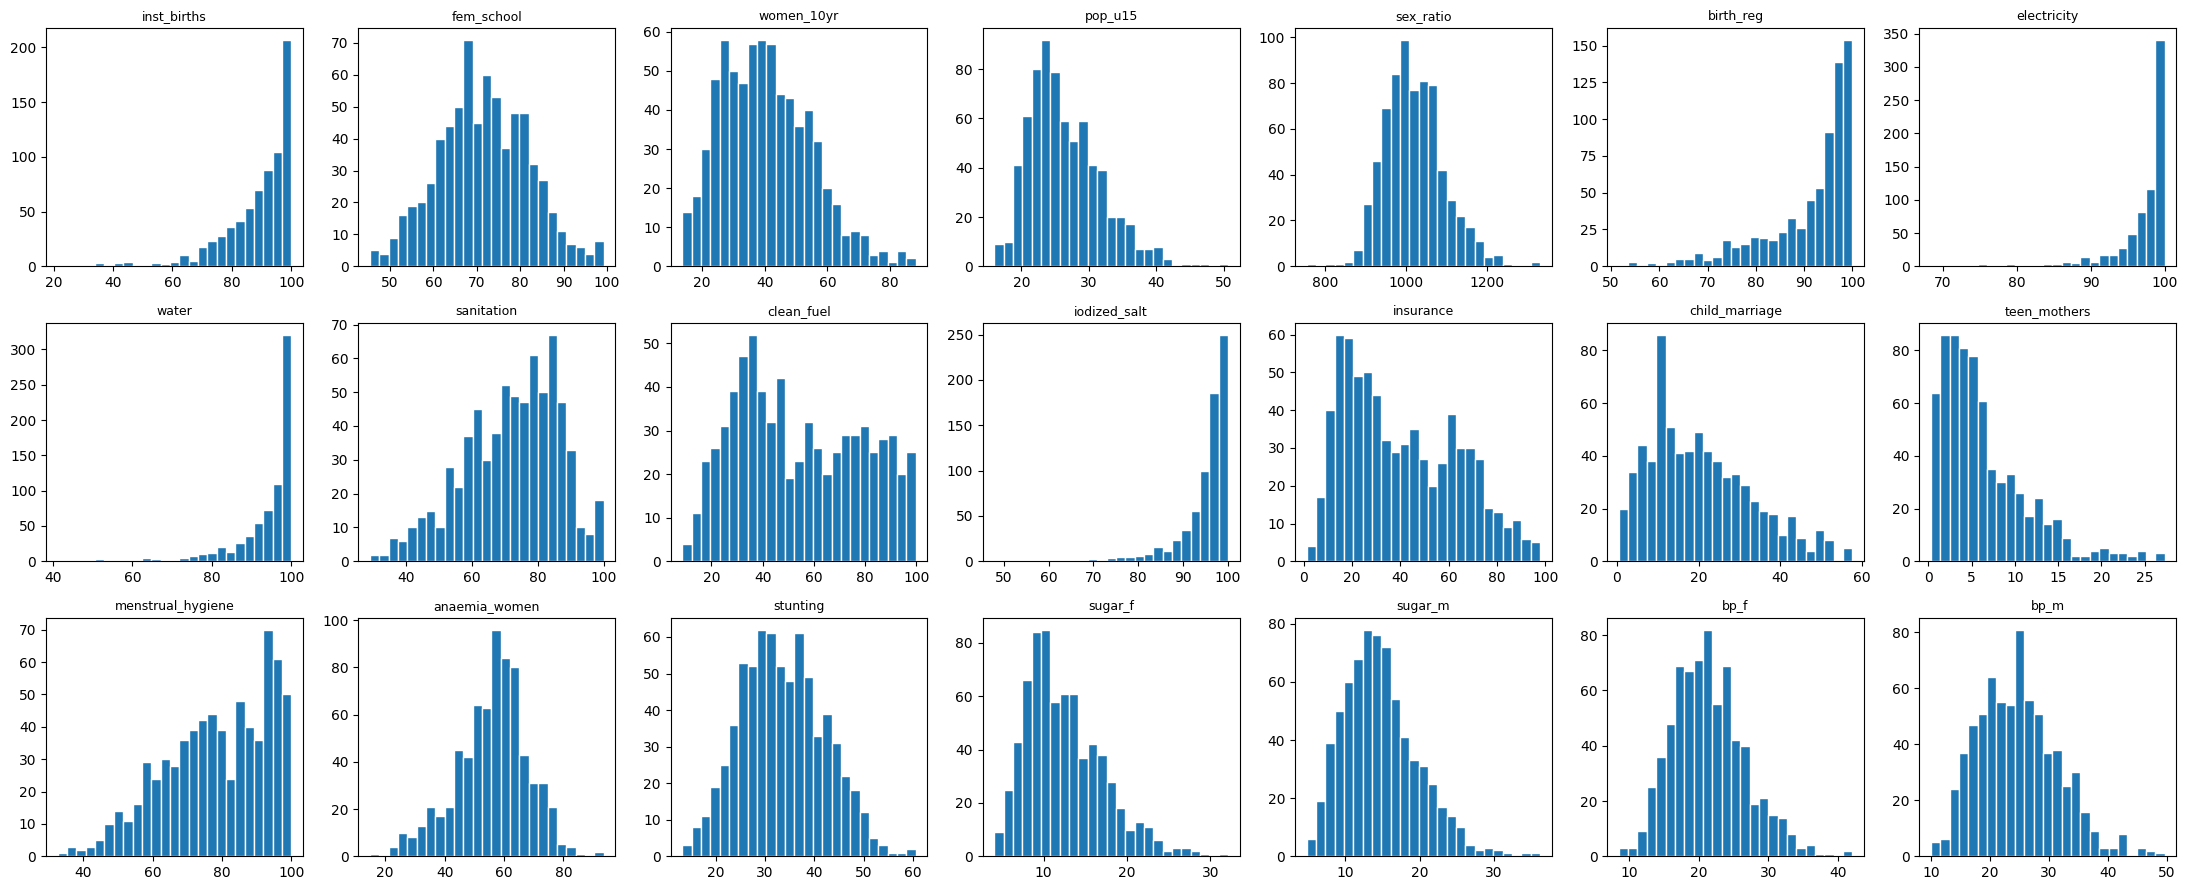

In [54]:
# ---- 4.2 Univariate: histograms ----
fig, axes = plt.subplots(3, 7, figsize=(22, 9))
for ax, c in zip(axes.ravel(), NUM_COLS):
    ax.hist(df5[c].dropna(), bins=25, edgecolor='white')
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

**Observations (4.2)**
- Institutional births, electricity, water, iodized salt and birth registration are strongly left-skewed with a pile-up at 100%. The target's ceiling is the reason predictions are clipped to 0-100 in Step 7.
- `teen_mothers` is right-skewed: most districts are below 10%.
- Education (`fem_school`, `women_10yr`), sanitation, stunting, anaemia and the blood-sugar and blood-pressure variables are roughly bell-shaped.
- `clean_fuel` and `insurance` are broad and spread out, with no single peak.

### 4.3 Relationships between variables
**Correlation matrix.** A heatmap of Pearson correlations for the target, features and burden indicators, plus the ranked correlation of every variable with the target.

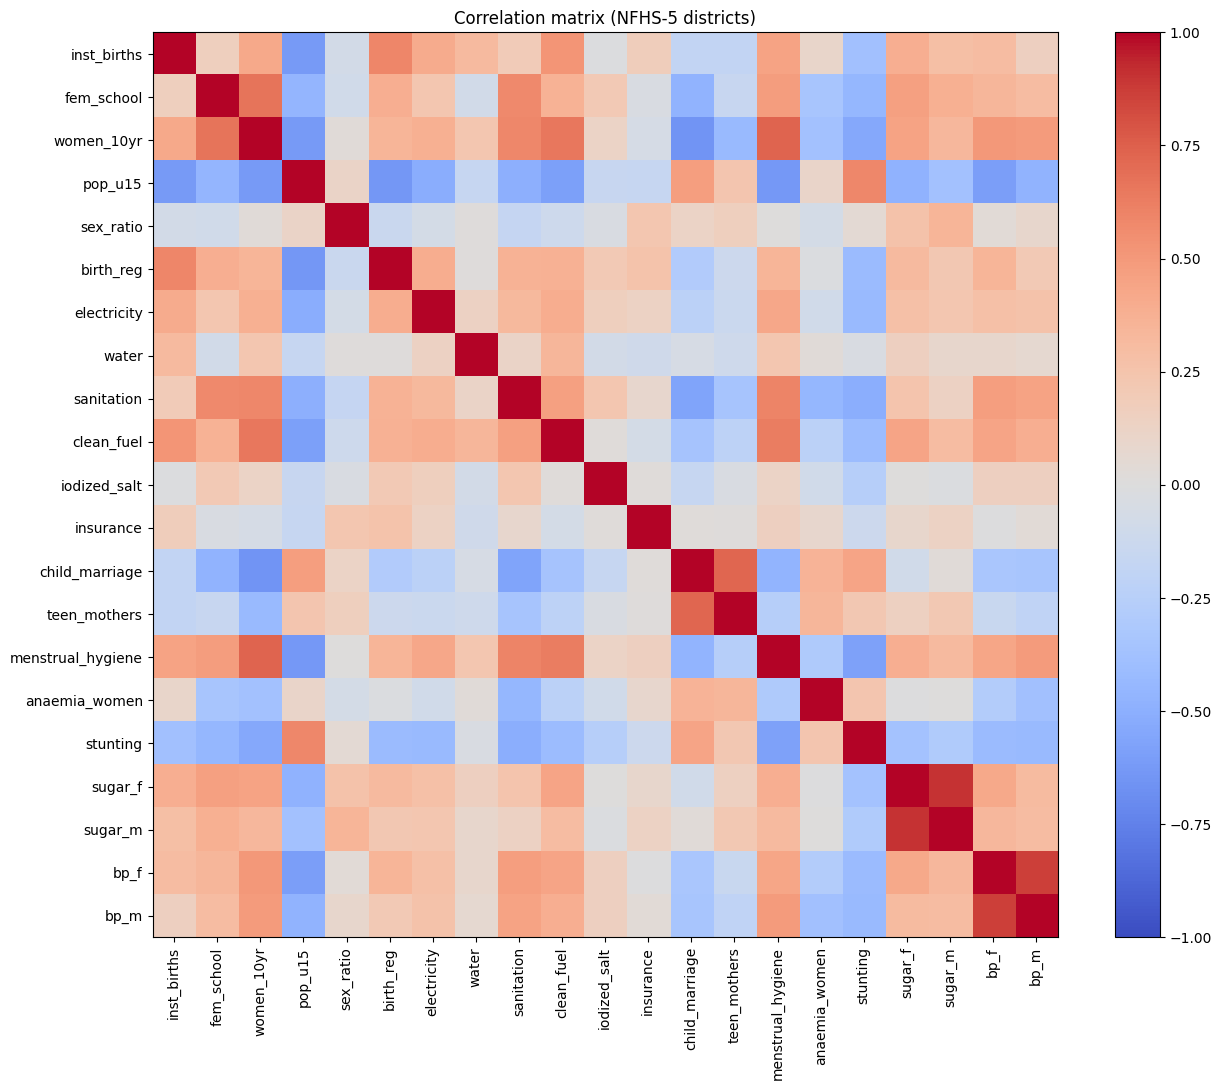


Features most correlated with the target:
pop_u15             -0.62
birth_reg            0.59
clean_fuel           0.52
menstrual_hygiene    0.45
women_10yr           0.42
electricity          0.40
sugar_f              0.39
stunting            -0.38
water                0.31
bp_f                 0.30
sugar_m              0.29
sanitation           0.19
teen_mothers        -0.19
child_marriage      -0.18
insurance            0.18
fem_school           0.16
bp_m                 0.15
anaemia_women        0.10
sex_ratio           -0.08
iodized_salt        -0.01
Name: inst_births, dtype: float64


In [55]:
# ---- 4.3a Correlation heatmap (matplotlib) ----
corr = df5[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS))); ax.set_xticklabels(NUM_COLS, rotation=90)
ax.set_yticks(range(len(NUM_COLS))); ax.set_yticklabels(NUM_COLS)
plt.colorbar(im, fraction=0.04)
ax.set_title('Correlation matrix (NFHS-5 districts)')
plt.tight_layout()
plt.savefig('figures/fig1_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFeatures most correlated with the target:")
print(corr[TARGET_COL].drop(TARGET_COL).sort_values(key=abs, ascending=False).round(2))

**Observations (4.3a)**
- The strongest correlations with the target are `pop_u15` (-0.62), `birth_reg` (0.59), `clean_fuel` (0.52), `menstrual_hygiene` (0.42), `women_10yr` (0.42) and `electricity` (0.40). A larger share of children in the population goes with fewer institutional births. This is probably a development and fertility proxy, and it is an association, not a cause.
- `iodized_salt` (-0.01) and `sex_ratio` (-0.08) show almost no linear relationship with the target.
- Most features are only moderately correlated with each other, which helps regression. Tight pairs: female and male blood sugar, female and male blood pressure, and child marriage with teen mothers.
- **[UPDATE]** The correlations involving `teen_mothers`, `child_marriage` and `menstrual_hygiene` changed slightly after the parsing fix. Use the values in your latest output.

**Scatter plots.** The target against the six features most correlated with it.

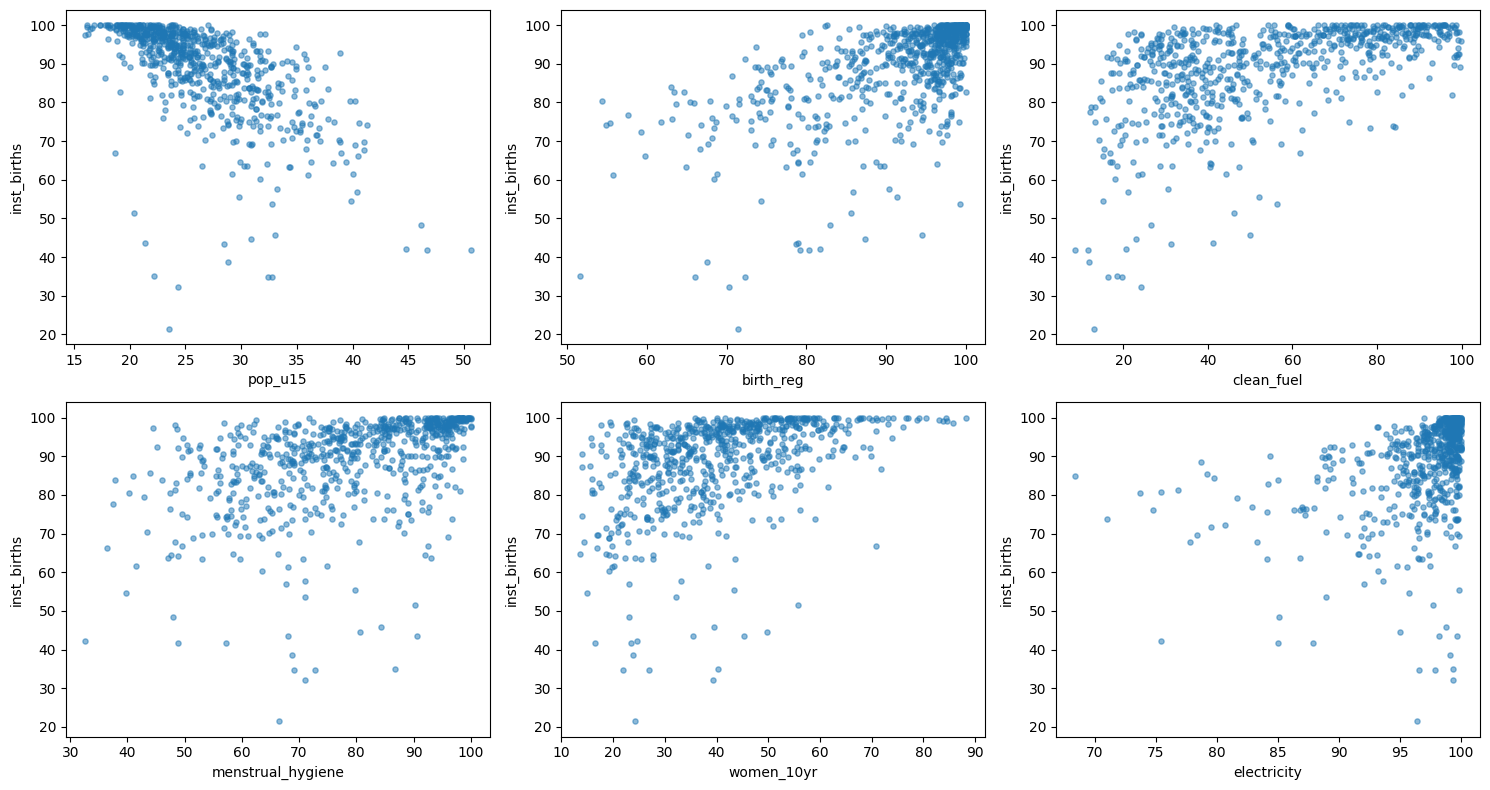

In [56]:
# ---- 4.3b Target vs the 6 strongest features ----
top6 = corr[TARGET_COL].drop(TARGET_COL)
top6 = top6[top6.index.isin(FEAT_COLS)].abs().sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), top6):
    ax.scatter(df5[c], df5[TARGET_COL], alpha=0.5, s=14)
    ax.set_xlabel(c); ax.set_ylabel(TARGET_COL)
plt.tight_layout()
plt.show()

**Observations (4.3b)**
- The relationships are not straight lines. They flatten at the 100% ceiling and the spread is widest at low feature values.
- Many districts with 90%+ electricity still have very low institutional births. Socioeconomic conditions alone do not explain them, and these are the districts the project looks for.
- A purely linear model will therefore struggle at the extremes. Step 7 tests that by also fitting a tree-based model.

### 4.4 State-wise comparison
Institutional births by state, sorted by median.

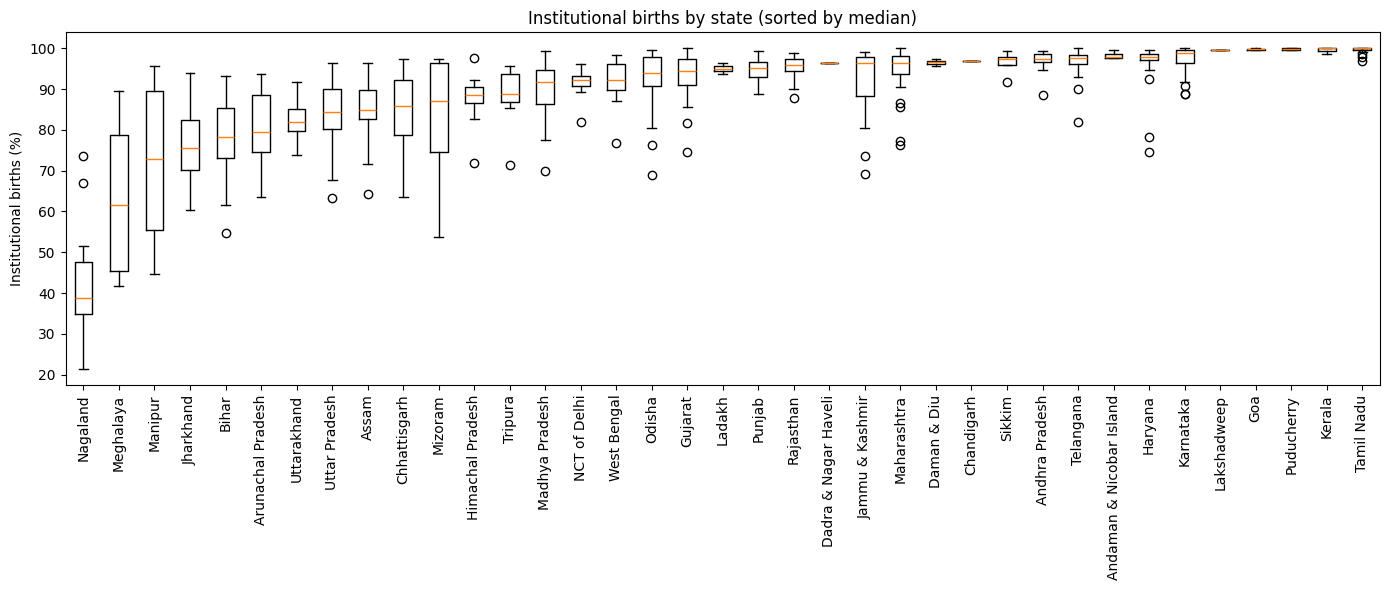

In [57]:
# ---- 4.4 State-wise comparison ----
order = df5.groupby('State')[TARGET_COL].median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 6))
ax.boxplot([df5.loc[df5['State'] == s, TARGET_COL] for s in order], tick_labels=order)
plt.xticks(rotation=90)
ax.set_ylabel('Institutional births (%)')
ax.set_title('Institutional births by state (sorted by median)')
plt.tight_layout()
plt.savefig('figures/fig2_state_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations (4.4)**
- The state has a strong influence. Nagaland's median is about 39% and Meghalaya's about 62%. Manipur, Jharkhand and Bihar are around 73-78%. Tamil Nadu, Kerala, Goa, Puducherry and Lakshadweep are close to 100%.
- Within-state spread is large in states such as Meghalaya, Manipur and Mizoram, so district-level targeting is worthwhile.
- Districts in the same state resemble each other. This is why validation in Step 7 splits by **state**, not by random district.

### 4.4b Need versus access
Anaemia, stunting and female blood sugar against institutional births.

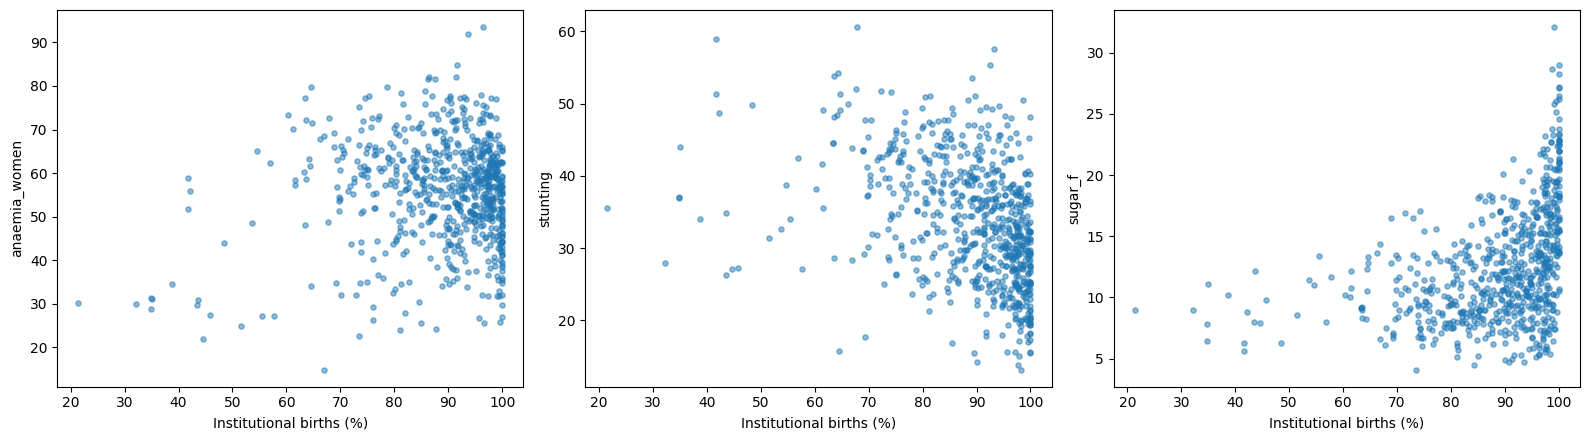

In [58]:
# ---- 4.4b Disease burden vs access ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ['anaemia_women', 'stunting', 'sugar_f']):
    ax.scatter(df5[TARGET_COL], df5[c], alpha=0.5, s=14)
    ax.set_xlabel('Institutional births (%)'); ax.set_ylabel(c)
plt.tight_layout()
plt.show()

**Observations (4.4b)**
- Anaemia is high everywhere (median 57%), including districts with near-universal institutional births, so it carries little signal on its own.
- Stunting is higher where institutional births are lower (correlation -0.38), which fits the idea of need. It is the better burden measure.
- Female blood sugar rises with institutional births (+0.39). One possible reason is more screening and affluence in better-served districts. This is a hypothesis I did not test. It is why blood sugar and blood pressure are **not** mixed into the main burden score and are used only as a secondary "chronic-care" view in Step 9.

## Step 5: Feature Engineering

### 5.1 Composite model features
| New feature | Built from | Why |
|---|---|---|
| `infra_index` | mean of electricity, water, sanitation, clean fuel | Several overlapping household-infrastructure variables become one summary of living conditions |
| `edu_index` | mean of female school attendance and women with 10+ years of schooling | Summarises education |
| `early_marriage_index` | mean of child marriage and teen mothers | Summarises early marriage and childbearing. `skipna=False` keeps it missing if either input is missing, so a district's index does not silently jump when only one input is available |

### 5.2 Burden scores (ranking only)
- `burden_nutrition` = average z-score of women's anaemia and child stunting (main need measure).
- `burden_ncd` = average z-score of blood sugar and blood pressure (secondary lens, with the screening caveat from Step 4).
- Neither is a model input, so there is no leakage and no circular logic.

### 5.3 Scaling and encoding
There are no categorical model inputs. Scaling and imputation happen **inside the model pipeline** and are fitted on training folds only (Step 7).

In [59]:
# ============ STEP 5: FEATURE ENGINEERING ============
assert 'FEAT_COLS' in globals(), "Run the outlier cell (df5 = nfhs5.copy()) and the Chandigarh/Lakshadweep fix first."

# 5.1 Composite model features
df5['infra_index'] = df5[['electricity', 'water', 'sanitation', 'clean_fuel']].mean(axis=1)
df5['edu_index'] = df5[['fem_school', 'women_10yr']].mean(axis=1)
df5['early_marriage_index'] = df5[['child_marriage', 'teen_mothers']].mean(axis=1, skipna=False)
ENG = ['infra_index', 'edu_index', 'early_marriage_index']
MODEL_FEATS = FEAT_COLS + ENG

# 5.2 Burden scores (ranking only, never model inputs, so no leakage)
z = lambda s: (s - s.mean()) / s.std()
df5['burden_nutrition'] = pd.concat([z(df5['anaemia_women']), z(df5['stunting'])], axis=1).mean(axis=1)
df5['burden_ncd'] = pd.concat([z(df5[c]) for c in ['sugar_f', 'sugar_m', 'bp_f', 'bp_m']], axis=1).mean(axis=1)

print(df5[ENG + [TARGET_COL]].corr()[TARGET_COL].round(2))
print("\nModel features:", len(MODEL_FEATS))

# ============ 5.3 SCALING AND ENCODING: checks and plan (fitting happens in Step 7) ============
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df5[MODEL_FEATS]

# Encoding: are there any non-numeric features?
print("Non-numeric model features:", list(X.select_dtypes(exclude='number').columns))   # expect []

# Missing values that the pipeline will fill
miss = X.isna().sum()
print("\nFeatures with missing values:")
print(miss[miss > 0])

# Scaling: how different are the feature scales?
rng = X.describe().loc[['min', 'max', 'std']].T.round(1)
display(rng.sort_values('std', ascending=False))
print("Std ranges from", rng['std'].min(), "to", rng['std'].max())

# The preprocessing used inside every model pipeline in Step 7
preprocess_plan = Pipeline([('imputer', SimpleImputer(strategy='median')),
                            ('scaler', StandardScaler())])
print("\nPreprocessing (fitted on training folds only, in Step 7):")
print(preprocess_plan)

infra_index             0.51
edu_index               0.34
early_marriage_index   -0.18
inst_births             1.00
Name: inst_births, dtype: float64

Model features: 17
Non-numeric model features: []

Features with missing values:
child_marriage           3
teen_mothers            19
menstrual_hygiene        2
early_marriage_index    19
dtype: int64


,min,max,std
sex_ratio,755.0,1332.0,73.3
clean_fuel,8.6,99.8,24.2
insurance,1.2,97.8,23.0
menstrual_hygiene,32.6,100.0,15.0
sanitation,29.2,99.9,14.3
women_10yr,13.6,88.2,14.2
child_marriage,0.5,57.6,12.5
edu_index,30.9,93.7,11.2
fem_school,45.4,99.2,10.3
infra_index,54.0,97.4,9.7


Std ranges from 4.4 to 73.3

Preprocessing (fitted on training folds only, in Step 7):
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


**Observations (5)**
- `infra_index` correlates 0.51 with the target and `edu_index` 0.34, so the summaries are informative. `early_marriage_index` is weaker (**[UPDATE]** use your latest value; it was about -0.15 before the fix).
- There are 17 candidate model features. Step 7 tests the model with and without `birth_reg`, so the final model has 16.
- The three indices are averages of their inputs, so they are strongly correlated with those inputs. This is one reason to include a regularised model (Ridge) in Step 7.

## Step 6: Inferential Statistics

### 6.1 Group comparisons
Districts are split at the median of a variable into "high" and "low" groups, and mean institutional births are compared. I use Welch's t-test (does not assume equal variances) and the Mann-Whitney U test (does not assume normality, since the target is skewed). Effect size is Cohen's d.
H0: the two group means are equal. H1: they differ. Significance level 0.05.

### 6.2 Confidence intervals
95% t-intervals for mean institutional births, for the overall data and for states with at least 5 districts.

### 6.3 Association tests
- Pearson and Spearman correlation of each model feature with the target, with a Bonferroni-adjusted threshold (0.05 divided by the number of tests).
- A chi-square test of independence between education level (low/high) and access level (below/above the median).

In [60]:
# ============ STEP 6: INFERENTIAL STATISTICS ============
# 6.1 Welch t-test + Mann-Whitney: high vs low districts (median split)
def compare(col):
    hi = df5.loc[df5[col] >= df5[col].median(), TARGET_COL]
    lo = df5.loc[df5[col] <  df5[col].median(), TARGET_COL]
    t, p = stats.ttest_ind(hi, lo, equal_var=False)
    _, pu = stats.mannwhitneyu(hi, lo)
    d = (hi.mean() - lo.mean()) / np.sqrt((hi.var(ddof=1) + lo.var(ddof=1)) / 2)
    print(f"{col:12s} high={hi.mean():.1f} (n={len(hi)}) low={lo.mean():.1f} (n={len(lo)}) "
          f"| t={t:.2f}, p={p:.1e} | MW p={pu:.1e} | Cohen d={d:.2f}")

print("\n--- 6.1 Group comparisons on institutional births ---")
for c in ['edu_index', 'clean_fuel', 'insurance']:
    compare(c)

# 6.2 95% confidence intervals
def ci95(x):
    x = x.dropna(); n = len(x)
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=x.mean(), scale=stats.sem(x))
    return n, x.mean(), lo, hi

rows = [(s, *ci95(g[TARGET_COL])) for s, g in df5.groupby('State') if len(g) >= 5]
ci_tbl = pd.DataFrame(rows, columns=['State', 'n', 'mean', 'ci_low', 'ci_high']).sort_values('mean')
print("\n--- 6.2 95% CI for mean institutional births (states with >=5 districts) ---")
display(ci_tbl.round(1))
print("All districts (unweighted):", [round(v, 1) for v in ci95(df5[TARGET_COL])])

# 6.3 Correlation significance (Bonferroni-adjusted)
rows = []
for c in MODEL_FEATS:
    s = df5[[c, TARGET_COL]].dropna()
    r, p = stats.pearsonr(s[c], s[TARGET_COL])
    rho, ps = stats.spearmanr(s[c], s[TARGET_COL])
    rows.append((c, len(s), r, p, rho, ps))
cor = pd.DataFrame(rows, columns=['feature', 'n', 'pearson_r', 'p', 'spearman_rho', 'p_spearman'])
cor['significant'] = cor['p'] < 0.05 / len(MODEL_FEATS)
print("\n--- 6.3 Correlation tests (Bonferroni alpha = %.4f) ---" % (0.05 / len(MODEL_FEATS)))
display(cor.sort_values('pearson_r', key=abs, ascending=False).round(4))

# 6.3b Chi-square: education level vs access level
tab = pd.crosstab(df5['edu_index'] >= df5['edu_index'].median(),
                  df5[TARGET_COL] >= df5[TARGET_COL].median())
tab.index = ['low edu', 'high edu']; tab.columns = ['below-median access', 'above-median access']
chi2, p, dof, exp = stats.chi2_contingency(tab)
print("\n--- 6.3b Chi-square ---")
display(tab)
print(f"chi2={chi2:.1f}, dof={dof}, p={p:.1e}, min expected count={exp.min():.0f}")


--- 6.1 Group comparisons on institutional births ---
edu_index    high=92.3 (n=354) low=85.1 (n=353) | t=8.30, p=5.6e-16 | MW p=7.7e-26 | Cohen d=0.62
clean_fuel   high=94.2 (n=354) low=83.2 (n=353) | t=13.79, p=3.5e-37 | MW p=3.9e-46 | Cohen d=1.04
insurance    high=90.2 (n=354) low=87.2 (n=353) | t=3.28, p=1.1e-03 | MW p=2.3e-05 | Cohen d=0.25

--- 6.2 95% CI for mean institutional births (states with >=5 districts) ---


,State,n,mean,ci_low,ci_high
18,Nagaland,11,43.3,32.9,53.7
15,Meghalaya,11,62.8,50.3,75.4
14,Manipur,9,71.2,55.4,87.1
9,Jharkhand,24,76.2,72.3,80.0
3,Bihar,38,77.8,75.0,80.7
1,Arunachal Pradesh,20,80.0,75.8,84.3
26,Uttarakhand,13,82.2,79.4,85.1
16,Mizoram,8,83.4,70.5,96.2
25,Uttar Pradesh,75,84.0,82.3,85.7
4,Chhattisgarh,27,84.5,80.7,88.3


All districts (unweighted): [707, np.float64(88.7), np.float64(87.8), np.float64(89.6)]

--- 6.3 Correlation tests (Bonferroni alpha = 0.0029) ---


,feature,n,pearson_r,p,spearman_rho,p_spearman,significant
2,pop_u15,707,-0.6242,0.0000,-0.7167,0.0000,True
4,birth_reg,707,0.5912,0.0000,0.6040,0.0000,True
8,clean_fuel,707,0.5230,0.0000,0.5844,0.0000,True
14,infra_index,707,0.5113,0.0000,0.6123,0.0000,True
13,menstrual_hygiene,705,0.4465,0.0000,0.5697,0.0000,True
1,women_10yr,707,0.4194,0.0000,0.5172,0.0000,True
5,electricity,707,0.4019,0.0000,0.5326,0.0000,True
15,edu_index,707,0.3385,0.0000,0.4468,0.0000,True
6,water,707,0.3142,0.0000,0.1727,0.0000,True
7,sanitation,707,0.1903,0.0000,0.3209,0.0000,True



--- 6.3b Chi-square ---


,below-median access,above-median access
low edu,226,127
high edu,123,231


chi2=59.4, dof=1, p=1.3e-14, min expected count=174


**Observations (6.1 group comparisons)**
- Education: high-education districts average 92.3% institutional births against 85.1% (t = 8.30, p of about 6e-16, Cohen's d = 0.62, a medium effect).
- Clean cooking fuel: 94.2% against 83.2% (t = 13.79, d = 1.04, a large effect). Clean fuel acts as a wealth proxy, so this is an association, not a cause.
- Health insurance: 90.2% against 87.2% (p = 0.0011, d = 0.25). Statistically significant but a small effect.
- The Mann-Whitney test agrees with the t-test in all three cases, so the conclusions do not depend on normality.
- **Caution:** districts in the same state are not independent, so the p-values are optimistic. The effect sizes are the safer guide.

**Observations (6.2 confidence intervals)**
- All districts: mean 88.7%, 95% CI 87.8% to 89.6%. This is an unweighted average across districts, not the national rate.
- Nagaland is 43.3% (32.9 to 53.7) and Meghalaya 62.8% (50.3 to 75.4). Their intervals are wide because each has only 11 districts. Jharkhand 76.2% (72.3 to 80.0) and Bihar 77.8% (75.0 to 80.7) have clearly lower means than Uttar Pradesh 84.0% (82.3 to 85.7), whose interval does not overlap theirs.
- Kerala (99.7%) and Tamil Nadu (99.6%) have very narrow intervals because almost every district is near 100%.
- Intervals for small or ceiling-capped states are approximate, since the t-interval assumes roughly normal means.

**Observations (6.3 association tests)**
- With a Bonferroni threshold of 0.0029, nearly all candidate features are significantly correlated with the target. `sex_ratio` and `iodized_salt` are not. **[UPDATE]** Re-read the table from your latest output: the rows for `teen_mothers`, `child_marriage` and `early_marriage_index` changed after the parsing fix.
- `pop_u15` (Pearson -0.62, Spearman -0.72) is the strongest. Pearson and Spearman differ noticeably for `water` (0.31 against 0.17), which suggests a few very low-water districts pull the linear figure up.
- With 707 districts even small correlations are significant, so significance is not importance. A correlation of about 0.1 explains only about 1% of the variance.
- Chi-square: education level and access level are associated (chi-square = 59.4, 1 degree of freedom, p of about 1e-14, smallest expected count 174, so the test's assumption holds). High-education districts are much more often above the median for access (231 vs 123). The effect is moderate (phi of about 0.29). Splitting at the median discards information, which is why the correlation tests were also run.

## Step 7: Model Building

### 7.1 Train/test split by state (no leakage)
Districts in the same state resemble each other, so a random split would put near-copies of a district in both train and test and make the model look better than it is. I hold out **whole states**: 20% of states form the test set (`GroupShuffleSplit`, seed 42). An `assert` confirms no state appears in both sets. The test set is used once, in Step 8.

### 7.2 Baseline
A mean predictor (always predicts the training mean). Any real model must beat it.

### 7.3 Models
- **Linear regression (OLS):** simple and interpretable.
- **Ridge regression:** adds a penalty on large coefficients, which helps with correlated features (alpha tuned).
- **Random Forest:** many decision trees; can capture curved relationships and interactions (depth and leaf size tuned).

### 7.4 Validation and tuning
5-fold **grouped** cross-validation on the training states only (`GroupKFold`), so each validation fold contains states the model has not seen. Hyperparameters are tuned by this CV. The imputer (median) and scaler sit **inside** each pipeline, so they are fitted on training folds only. Predictions are clipped to 0-100 because the target is a percentage.

### 7.5 Two feature sets
Each model is run with all 17 features and without `birth_reg`. Hospital births usually get registered, so `birth_reg` may partly follow from the target; the comparison shows whether it matters.

### 7.6 Metrics
RMSE (main, in percentage points), MAE, and R-squared.

In [27]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------- 7.1 State-wise train / test split (no state in both) ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df5, df5[TARGET_COL], groups=df5['State']))
train, test = df5.iloc[train_idx].copy(), df5.iloc[test_idx].copy()
assert set(train['State']).isdisjoint(set(test['State'])), "State leakage!"
print("Train:", len(train), "districts,", train['State'].nunique(), "states")
print("Test :", len(test), "districts,", test['State'].nunique(), "states ->", sorted(test['State'].unique()))

# ---------- Scorers (predictions clipped to the valid 0-100 range) ----------
def rmse_c(y, p): return np.sqrt(mean_squared_error(y, np.clip(p, 0, 100)))
def mae_c(y, p):  return mean_absolute_error(y, np.clip(p, 0, 100))
def r2_c(y, p):   return r2_score(y, np.clip(p, 0, 100))
scoring = {'rmse': make_scorer(rmse_c, greater_is_better=False),
           'mae':  make_scorer(mae_c,  greater_is_better=False),
           'r2':   make_scorer(r2_c)}

# ---------- 7.2-7.4 Models (imputer and scaler inside the pipeline) ----------
def make_pipe(model, scale=False):
    steps = [('imp', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('sc', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

models = {
    'Baseline (mean)': (make_pipe(DummyRegressor(strategy='mean')), {}),
    'Linear (OLS)':    (make_pipe(LinearRegression(), scale=True), {}),
    'Ridge':           (make_pipe(Ridge(), scale=True),
                        {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Random Forest':   (make_pipe(RandomForestRegressor(n_estimators=300,
                                                        random_state=RANDOM_STATE, n_jobs=1)),
                        {'model__max_depth': [3, 5, 8, None],
                         'model__min_samples_leaf': [1, 3, 5, 10]}),
}
feature_sets = {'all 17 features': MODEL_FEATS,
                'without birth_reg': [f for f in MODEL_FEATS if f != 'birth_reg']}

# ---------- 7.5 Grouped cross-validation + tuning on the TRAIN states only ----------
cv = GroupKFold(n_splits=5)
results, fitted = [], {}
for fs_name, feats in feature_sets.items():
    for m_name, (pipe, grid) in models.items():
        gs = GridSearchCV(pipe, grid, scoring=scoring, refit='rmse', cv=cv,
                          return_train_score=True, n_jobs=-1)
        gs.fit(train[feats], train[TARGET_COL], groups=train['State'])
        i, r = gs.best_index_, gs.cv_results_
        results.append({
            'features': fs_name, 'model': m_name, 'best_params': gs.best_params_,
            'train_RMSE': -r['mean_train_rmse'][i],
            'val_RMSE':   -r['mean_test_rmse'][i],
            'val_RMSE_sd': r['std_test_rmse'][i],
            'val_MAE':    -r['mean_test_mae'][i],
            'val_R2':      r['mean_test_r2'][i]})
        fitted[(fs_name, m_name)] = gs

res = pd.DataFrame(results)
res['overfit_gap'] = res['val_RMSE'] - res['train_RMSE']
pd.set_option('display.width', 200, 'display.max_colwidth', 60)
display(res.round(2))

Train: 533 districts, 29 states
Test : 174 districts, 8 states -> ['Bihar', 'Chhattisgarh', 'Jammu & Kashmir', 'Ladakh', 'Nagaland', 'Odisha', 'Rajasthan', 'Uttarakhand']


,features,model,best_params,train_RMSE,val_RMSE,val_RMSE_sd,val_MAE,val_R2,overfit_gap
0,all 17 features,Baseline (mean),{},10.40,10.67,2.44,8.36,-0.58,0.27
1,all 17 features,Linear (OLS),{},5.49,6.67,2.00,4.99,0.38,1.18
2,all 17 features,Ridge,{'model__alpha': 100},5.72,6.64,1.75,4.80,0.41,0.93
3,all 17 features,Random Forest,"{'model__max_depth': 3, 'model__min_samples_leaf': 3}",5.13,7.18,1.89,5.27,0.34,2.05
4,without birth_reg,Baseline (mean),{},10.40,10.67,2.44,8.36,-0.58,0.27
5,without birth_reg,Linear (OLS),{},5.70,6.72,1.47,5.02,0.35,1.02
6,without birth_reg,Ridge,{'model__alpha': 0.01},5.70,6.72,1.47,5.02,0.35,1.02
7,without birth_reg,Random Forest,"{'model__max_depth': 3, 'model__min_samples_leaf': 10}",5.53,7.14,1.73,5.18,0.35,1.61


**Observations (7)**
- The split gave 533 training districts (29 states) and 174 test districts (8 states: Bihar, Chhattisgarh, Jammu & Kashmir, Ladakh, Nagaland, Odisha, Rajasthan, Uttarakhand).

**Cross-validation results (without `birth_reg`)**

| Model | Best parameters | Train RMSE | Validation RMSE | Validation R-squared |
|---|---|---|---|---|
| Baseline (mean) | none | 10.40 | 10.67 | -0.58 |
| Linear (OLS) | none | 5.78 | 6.74 | 0.37 |
| Ridge | alpha = 1 | 5.79 | 6.74 | 0.37 |
| Random Forest | max depth 3, min leaf 10 | 5.53 | 7.14 | 0.35 |

- Every model beats the baseline (validation RMSE 6.74 against 10.67, about 37% lower). The baseline's R-squared is negative because held-out states have a different average from the training states.
- A Random Forest did **not** beat the linear models, which I had expected it to. Possible reasons, not tested: 533 districts is small for a forest, and trees cannot predict beyond the range seen in training states.
- Dropping `birth_reg` changed Ridge's validation RMSE only from 6.65 to 6.74, which is within fold-to-fold variation (standard deviation of about 1.7).
- **Decisions, recorded before looking at the test set:**
  1. The final model is **Ridge without `birth_reg`**: the CV scores are equivalent within noise, and it is simpler, easier to explain and less circular.
  2. Differences between OLS, Ridge and Random Forest are within one fold standard deviation, so I do not claim any one is "significantly" better.

## Step 8: Model Evaluation and Overfitting Analysis

### 8.1 Test-set evaluation (done once)
The models were chosen using cross-validation on the training states. The 8 held-out test states are now used for one final check. Nothing was tuned on them.

In [28]:
from sklearn.model_selection import cross_validate

FS = 'without birth_reg'
FINAL_FEATS = feature_sets[FS]
ytest = test[TARGET_COL]
Xtr, ytr, gtr = train[FINAL_FEATS], train[TARGET_COL], train['State']

# ---------- 8.1 Test-set evaluation (done once; models were chosen by CV) ----------
cv_val = res[res['features'] == FS].set_index('model')['val_RMSE']
rows = []
for m in models:
    est = fitted[(FS, m)].best_estimator_      # already refit on all training states
    p = np.clip(est.predict(test[FINAL_FEATS]), 0, 100)
    rows.append({'model': m, 'CV_RMSE': cv_val[m], 'test_RMSE': rmse_c(ytest, p),
                 'test_MAE': mae_c(ytest, p), 'test_R2': r2_c(ytest, p)})
print("8.1 Test-set results (selection was made before this step):")
display(pd.DataFrame(rows).round(2))






8.1 Test-set results (selection was made before this step):


,model,CV_RMSE,test_RMSE,test_MAE,test_R2
0,Baseline (mean),10.67,15.83,10.55,-0.13
1,Linear (OLS),6.72,13.40,8.18,0.19
2,Ridge,6.72,13.40,8.18,0.19
3,Random Forest,7.14,14.19,8.98,0.09


**Observations (8.1)**

| Model | CV RMSE | Test RMSE | Test MAE | Test R-squared |
|---|---|---|---|---|
| Baseline (mean) | 10.67 | 15.83 | 10.55 | -0.13 |
| Linear (OLS) | 6.74 | 13.48 | 8.47 | 0.18 |
| Ridge | 6.74 | 13.49 | 8.49 | 0.18 |
| Random Forest | 7.14 | 14.19 | 8.98 | 0.09 |

- The ranking on the test states matches the CV ranking, so choosing models by grouped CV was sound.
- The test error is about twice the CV error. One state explains this (see 8.3 and 8.5): Nagaland.

### 8.2 Overfitting analysis
Training and validation error as model flexibility changes. A growing gap between them signals overfitting.
- **Random Forest:** tree depth from 1 (very simple) to unlimited.
- **Ridge:** regularisation strength alpha from 0.01 to 10,000.

,max_depth,train_RMSE,val_RMSE
0,1,7.45,7.48
1,2,6.03,7.05
2,3,5.20,7.19
3,4,4.41,7.29
4,6,3.16,7.40
5,8,2.50,7.46
6,12,2.17,7.50
7,None,2.16,7.52


,alpha,train_RMSE,val_RMSE
0,0.01,5.70,6.72
1,0.1,5.70,6.72
2,1,5.70,6.72
3,10,5.72,6.73
4,100,5.99,6.93
5,1000,7.42,7.89
6,10000,9.49,9.77


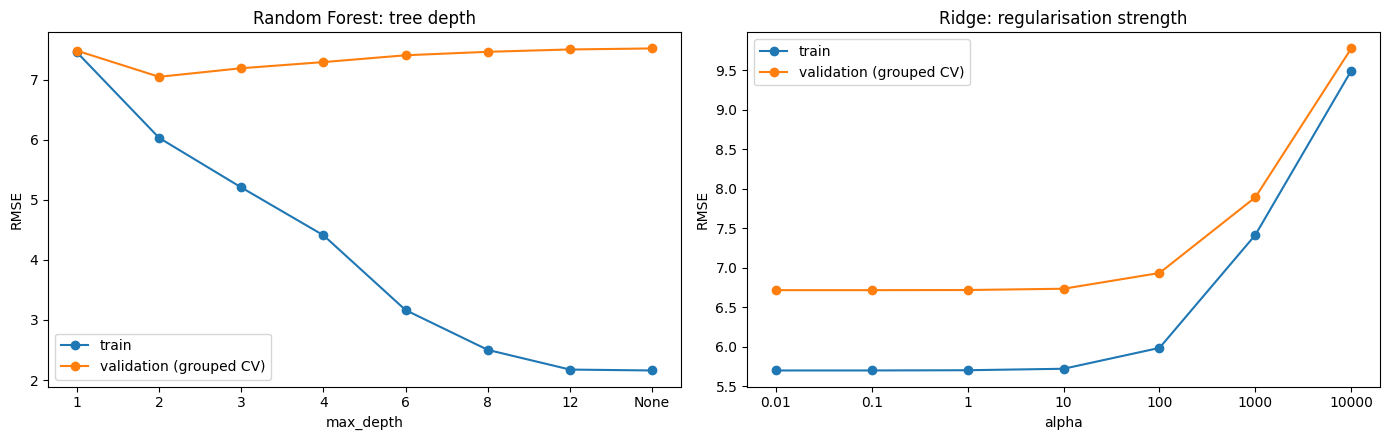

In [29]:
# ---------- 8.2 Overfitting analysis ----------
def curve(make_est, values, label):
    out = []
    for v in values:
        r = cross_validate(make_est(v), Xtr, ytr, groups=gtr, cv=GroupKFold(5),
                           scoring={'rmse': make_scorer(rmse_c, greater_is_better=False)},
                           return_train_score=True, n_jobs=-1)
        out.append({label: str(v), 'train_RMSE': -r['train_rmse'].mean(),
                    'val_RMSE': -r['test_rmse'].mean()})
    return pd.DataFrame(out)

rf_curve = curve(lambda d: make_pipe(RandomForestRegressor(
    n_estimators=200, max_depth=d, random_state=RANDOM_STATE, n_jobs=1)),
    [1, 2, 3, 4, 6, 8, 12, None], 'max_depth')
ridge_curve = curve(lambda a: make_pipe(Ridge(alpha=a), scale=True),
                    [0.01, 0.1, 1, 10, 100, 1000, 10000], 'alpha')
display(rf_curve.round(2)); display(ridge_curve.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, cdf, lab, ttl in [(axes[0], rf_curve, 'max_depth', 'Random Forest: tree depth'),
                          (axes[1], ridge_curve, 'alpha', 'Ridge: regularisation strength')]:
    ax.plot(cdf[lab], cdf['train_RMSE'], marker='o', label='train')
    ax.plot(cdf[lab], cdf['val_RMSE'], marker='o', label='validation (grouped CV)')
    ax.set_xlabel(lab); ax.set_ylabel('RMSE'); ax.set_title(ttl); ax.legend()
plt.tight_layout()
plt.savefig('figures/fig3_overfitting_curves.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations (8.2)**
- **Random Forest overfits.** Training RMSE falls from 7.45 (depth 1) to 2.16 (unlimited depth), while validation RMSE stays at 7.0-7.5. The model memorises training districts without improving on new states. Depth 1 underfits (train and validation both about 7.45). Validation is best at depth 2 (7.05), still worse than Ridge.
- **Ridge** is flat at 6.74 for alpha 0.01 to 10, so the regularisation barely matters here and Ridge behaves much like OLS. Above alpha 100 both curves rise: too much shrinkage underfits. The train-validation gap is only about 1 point, so overfitting is mild.
- Conclusion: a simple regularised linear model generalises as well as or better than a complex one on this small, state-clustered dataset.

### 8.3 Residual analysis
Actual against predicted values for the test states, the residual distribution, the ten districts with the largest errors, and the error by state. Residual = actual minus predicted, so a negative residual means access is lower than expected.

Final model alpha: {'model__alpha': 0.01}


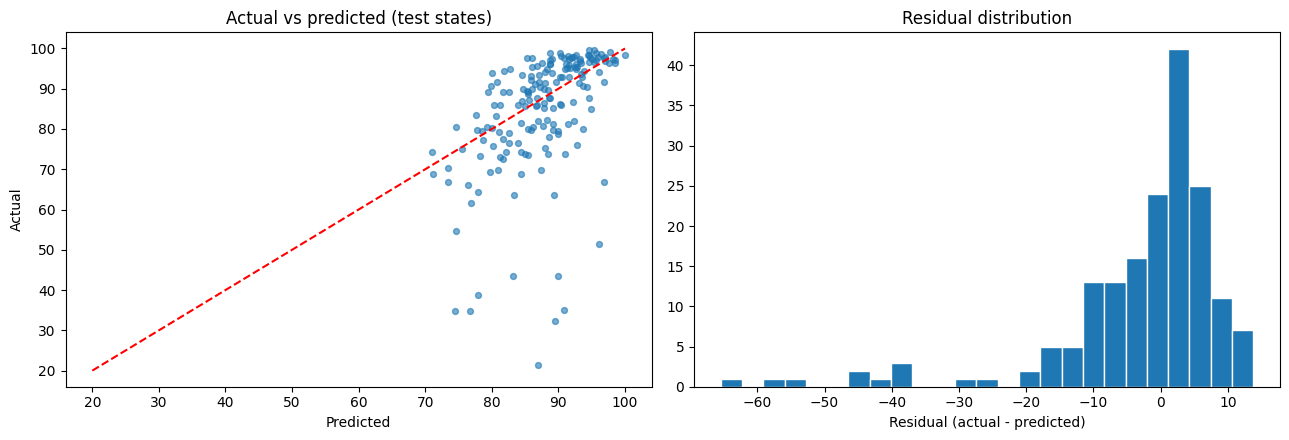

Worst 10 districts by |residual|:


,State,District,inst_births,pred,resid
429,Nagaland,Mon,21.4,86.9,-65.5
431,Nagaland,Phek,32.2,89.6,-57.4
434,Nagaland,Zunheboto,35.0,90.8,-55.8
433,Nagaland,Wokha,43.6,89.9,-46.3
428,Nagaland,Mokokchung,51.5,96.0,-44.5
425,Nagaland,Kiphire,34.8,76.8,-42.0
430,Nagaland,Peren,43.5,83.2,-39.7
432,Nagaland,Tuensang,34.8,74.4,-39.6
427,Nagaland,Longleng,38.7,77.9,-39.2
426,Nagaland,Kohima,66.9,96.8,-29.9


Error by held-out state:


,n,mean_resid,RMSE
State,,,
Bihar,38,-2.1,7.3
Chhattisgarh,27,-5.3,9.1
Jammu & Kashmir,20,1.7,5.6
Ladakh,2,-0.9,1.5
Nagaland,11,-43.4,45.2
Odisha,30,2.7,6.5
Rajasthan,33,5.5,6.5
Uttarakhand,13,-9.0,9.8


In [30]:
# ---------- 8.3 Residual analysis (final model on the test states) ----------
final = fitted[(FS, 'Ridge')].best_estimator_
print("Final model alpha:", fitted[(FS, 'Ridge')].best_params_)
test['pred'] = np.clip(final.predict(test[FINAL_FEATS]), 0, 100)
test['resid'] = test[TARGET_COL] - test['pred']      # negative = below expectation

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(test['pred'], test[TARGET_COL], alpha=0.6, s=18)
axes[0].plot([20, 100], [20, 100], 'r--')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title('Actual vs predicted (test states)')
axes[1].hist(test['resid'], bins=25, edgecolor='white')
axes[1].set_xlabel('Residual (actual - predicted)'); axes[1].set_title('Residual distribution')
plt.tight_layout()
plt.savefig('figures/fig4_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

print("Worst 10 districts by |residual|:")
display(test.assign(abs_res=test['resid'].abs()).nlargest(10, 'abs_res')
        [['State', 'District', TARGET_COL, 'pred', 'resid']].round(1))
st = test.groupby('State')['resid'].agg(n='size', mean_resid='mean',
                                        RMSE=lambda r: np.sqrt((r ** 2).mean()))
print("Error by held-out state:"); display(st.round(1))


**Observations (8.3)**
- The residual distribution has a long left tail, and it is entirely Nagaland. The model predicts 75-97% institutional births for districts whose actual figure is 21-67%. The ten worst errors are all Nagaland districts (Mon -64.6, Phek -57.5, Zunheboto -54.6, Wokha -45.9, Mokokchung -43.8).
- Error by held-out state: Nagaland RMSE 44.8 (mean residual -43.1). The others range from 1.2 (Ladakh, only 2 districts) to 9.2 (Uttarakhand): Bihar 7.5, Chhattisgarh 9.1, Jammu & Kashmir 5.5, Odisha 6.9, Rajasthan 7.8.
- **Two readings, both plausible:** (a) these districts have far lower access than their socioeconomic profile suggests, which is exactly the signal the project looks for; (b) the model cannot extrapolate to a state lower than any training state. The data cannot separate the two.
- State-level mean residuals differ (+7.0 for Rajasthan, -8.3 for Uttarakhand), so residuals mix real under-service with state-wide factors that are not in the data.
- Typical error is 6-9 percentage points, so only large negative residuals should be read as under-service.

### 8.4 Out-of-time check: train on NFHS-4, predict NFHS-5
A Ridge model is trained on NFHS-4 data (575 districts) and used to predict NFHS-5. This is a stability check, not independent validation, because the same districts appear in both rounds. It is compared with two simple benchmarks: carrying forward each district's NFHS-4 value, and the NFHS-4 mean.

In [31]:
# ---------- 8.4 Out-of-time check: train on NFHS-4, predict NFHS-5 ----------
n4 = nfhs4.copy()
n4['infra_index'] = n4[['electricity', 'water', 'sanitation', 'clean_fuel']].mean(axis=1)
n4['edu_index'] = n4[['fem_school', 'women_10yr']].mean(axis=1)
n4['early_marriage_index'] = n4[['child_marriage', 'teen_mothers']].mean(axis=1, skipna=False)
n4 = n4.dropna(subset=[TARGET_COL])

key = ['State', 'District']
ev = df5.merge(n4[key + [TARGET_COL]].rename(columns={TARGET_COL: 'prev'}), on=key)
print(f"\nNFHS-4 training districts: {len(n4)} | matched in NFHS-5: {len(ev)}")

pipe4 = make_pipe(Ridge(alpha=fitted[(FS, 'Ridge')].best_params_['model__alpha']), scale=True)
pipe4.fit(n4[FINAL_FEATS], n4[TARGET_COL])
p4 = np.clip(pipe4.predict(ev[FINAL_FEATS]), 0, 100)
y5 = ev[TARGET_COL]
print(f"Mean institutional births: NFHS-4 = {ev['prev'].mean():.1f} -> NFHS-5 = {y5.mean():.1f}")
print(f"Ridge trained on NFHS-4   : RMSE={rmse_c(y5, p4):.2f}, MAE={mae_c(y5, p4):.2f}, "
      f"R2={r2_c(y5, p4):.2f}, mean error={np.mean(y5 - p4):.2f}")
print(f"Carry forward NFHS-4 value: RMSE={rmse_c(y5, ev['prev']):.2f}, MAE={mae_c(y5, ev['prev']):.2f}")
print(f"NFHS-4 mean baseline      : RMSE={rmse_c(y5, np.full(len(y5), n4[TARGET_COL].mean())):.2f}")


NFHS-4 training districts: 575 | matched in NFHS-5: 575
Mean institutional births: NFHS-4 = 79.2 -> NFHS-5 = 88.9
Ridge trained on NFHS-4   : RMSE=11.88, MAE=8.83, R2=0.00, mean error=6.31
Carry forward NFHS-4 value: RMSE=13.12, MAE=9.91
NFHS-4 mean baseline      : RMSE=15.36


**Observations (8.4)**
- Mean institutional births rose from 79.2% (NFHS-4) to 88.9% (NFHS-5) across the 575 matched districts.
- The NFHS-4 Ridge model gives RMSE 11.82 on NFHS-5, better than carrying forward last round's value (13.12) or the NFHS-4 mean (15.36). R-squared is about 0.01 and the mean error is +6.27 percentage points: the model underpredicts, because the whole country improved.
- The relationships learned in 2015-16 still carry over in rank terms (see 8.5), but the model does not predict the level of access well across time. It estimates *expected* access from conditions; it is not a forecasting model.

### 8.5 Post-hoc diagnostics
Two descriptive checks, **not used to change any decision**: test error without Nagaland, and the rank correlation between NFHS-4 predictions and NFHS-5 actuals.

In [32]:
# 8.5 Post-hoc diagnostics (descriptive only; no model decisions are based on these)
m = test['State'] != 'Nagaland'
print(f"Test without Nagaland (n={m.sum()}): Ridge RMSE = {rmse_c(test.loc[m, TARGET_COL], test.loc[m, 'pred']):.2f}")
base_p = fitted[(FS, 'Baseline (mean)')].best_estimator_.predict(test.loc[m, FINAL_FEATS])
print(f"                                      Baseline RMSE = {rmse_c(test.loc[m, TARGET_COL], base_p):.2f}")

from scipy.stats import spearmanr
print("\nNFHS-4 -> NFHS-5: Spearman rank correlation (predicted vs actual) =",
      round(spearmanr(p4, y5)[0], 2))
print("RMSE after removing the average shift (diagnostic only, uses NFHS-5 mean):",
      round(rmse_c(y5, p4 + np.mean(y5 - p4)), 2))

Test without Nagaland (n=163): Ridge RMSE = 7.34
                                      Baseline RMSE = 10.27

NFHS-4 -> NFHS-5: Spearman rank correlation (predicted vs actual) = 0.73
RMSE after removing the average shift (diagnostic only, uses NFHS-5 mean): 9.56


**Observations (8.5)**
- Without Nagaland, Ridge's test RMSE is **7.34** (baseline 10.27, about 29% lower). This is close to the CV figure of 6.74, so the high overall test error comes from one state, not from general failure.
- The Spearman rank correlation between predicted and actual NFHS-5 values is 0.73: the NFHS-4 model orders districts reasonably well even though its levels are off. Rank order is what a shortlist needs.
- After removing the average shift between rounds, RMSE falls from 11.82 to 9.56. This figure uses the NFHS-5 mean, so it is a diagnostic only.

## Step 9: Opportunity Ranking, Conclusions and Limitations

### 9.1 Expected access for every district
For the ranking, every district needs an "expected" value from a model that has not seen its state. I use **out-of-fold** predictions from state-grouped 5-fold cross-validation with the final Ridge model. The test set is not touched.

### 9.2 Opportunity score
- **Gap** = expected minus actual institutional births, set to 0 if the district is above expectation.
- **Burden percentile** = rank of the district's nutrition burden (anaemia and stunting), from 0 to 1.
- **Opportunity score = gap x burden percentile.** A district with high need but no gap is already served. A district with a gap but low need is a weaker market. The product is highest where both hold.
- **Eligibility threshold:** only districts with a gap of at least 13.5 percentage points (about twice the grouped-CV error of 6.74) are ranked, so shortfalls within model noise are not read as under-service.

In [33]:
from sklearn.model_selection import cross_val_predict

# ---------- 9.1 Expected access for every district ----------
alpha = fitted[(FS, 'Ridge')].best_params_['model__alpha']
oof_model = make_pipe(Ridge(alpha=alpha), scale=True)
df5['expected'] = np.clip(cross_val_predict(
    oof_model, df5[FINAL_FEATS], df5[TARGET_COL],
    groups=df5['State'], cv=GroupKFold(n_splits=5)), 0, 100)
df5['gap'] = (df5['expected'] - df5[TARGET_COL]).clip(lower=0)   # shortfall vs expectation, in pp
print("Out-of-fold RMSE, all 707 districts:", round(rmse_c(df5[TARGET_COL], df5['expected']), 2))

# ---------- 9.2 Opportunity score = shortfall x burden percentile ----------
df5['burden_pct'] = df5['burden_nutrition'].rank(pct=True)   # anaemia + stunting
df5['ncd_pct'] = df5['burden_ncd'].rank(pct=True)            # sugar + BP (second lens)
df5['opp_score'] = df5['gap'] * df5['burden_pct']
df5['opp_score_ncd'] = df5['gap'] * df5['ncd_pct']

GAP_MIN = 13.5    # about 2x the grouped-CV RMSE (6.74): smaller shortfalls are within model noise
elig = df5[df5['gap'] >= GAP_MIN]
print(f"Districts with a shortfall beyond noise (>= {GAP_MIN} pp): {len(elig)} of {len(df5)}")

cols = ['State', 'District', TARGET_COL, 'expected', 'gap', 'burden_pct', 'opp_score']
top = elig.nlargest(20, 'opp_score')[cols].round(2)
display(top)



Out-of-fold RMSE, all 707 districts: 9.14
Districts with a shortfall beyond noise (>= 13.5 pp): 33 of 707


,State,District,inst_births,expected,gap,burden_pct,opp_score
111,Chhattisgarh,Bastar,63.5,88.65,25.15,0.99,24.94
113,Chhattisgarh,Bijapur,63.6,88.26,24.66,1.00,24.55
231,Jharkhand,Dumka,60.3,82.15,21.85,0.89,19.54
229,Jharkhand,Deoghar,61.3,78.12,16.82,0.91,15.32
434,Nagaland,Zunheboto,35.0,88.51,53.51,0.29,15.29
570,Telangana,Komaram Bheem Asifabad,82.0,100.00,18.00,0.82,14.74
95,Bihar,Purba Champaran,61.5,77.22,15.72,0.89,13.94
45,Assam,Dhubri,64.2,78.50,14.30,0.94,13.51
401,Meghalaya,South West Khasi Hills,41.7,55.92,14.22,0.94,13.40
85,Bihar,Kishanganj,54.6,69.94,15.34,0.80,12.33


**Observations (9.1 to 9.2)**
- Out-of-fold RMSE across all 707 districts is 9.14.
- 33 of 707 districts (4.7%) have a shortfall of at least 13.5 percentage points. By state: Nagaland 11, Chhattisgarh 3, Manipur 3, Meghalaya 3, Himachal Pradesh 2, Bihar 2, Jharkhand 2, Assam 1, Arunachal Pradesh 1, Madhya Pradesh 1.
- The top five by opportunity score are Bastar (actual 63.5% against 88.7% expected, burden percentile 0.99), Bijapur (63.6% vs 88.3%, 1.00), Dumka (60.3% vs 82.2%, 0.89), Deoghar (61.3% vs 78.1%, 0.91) and Zunheboto (35.0% vs 88.5%, 0.29).
- Bastar, Bijapur and Dumka combine a gap of 21-25 points with among the highest nutrition burdens.
- Nagaland has the largest raw gaps (40-64 points) but low scores, because its measured nutrition burden is low (burden percentile 0.11-0.29 for Mon, Kiphire, Longleng and Tuensang). The ranking depends on how need is defined.
- Komaram Bheem Asifabad, Lahul and Spiti, and Kinnaur have an expected value of 100% (the model's cap), so their gap is measured from the ceiling and is less reliable. Lahul and Spiti and Kinnaur are also small districts where survey error is probably larger.
- The secondary chronic-care ranking (blood sugar and blood pressure) is dominated by Nagaland because Nagaland's gaps are so large. Read it with the screening caveat from Step 4.

### 9.3 Robustness of the shortlist
Is the shortlist stable? I repeat the selection with a stricter threshold of twice the out-of-fold RMSE (18.3 points), and compare it with a ranking by access gap alone that ignores burden.

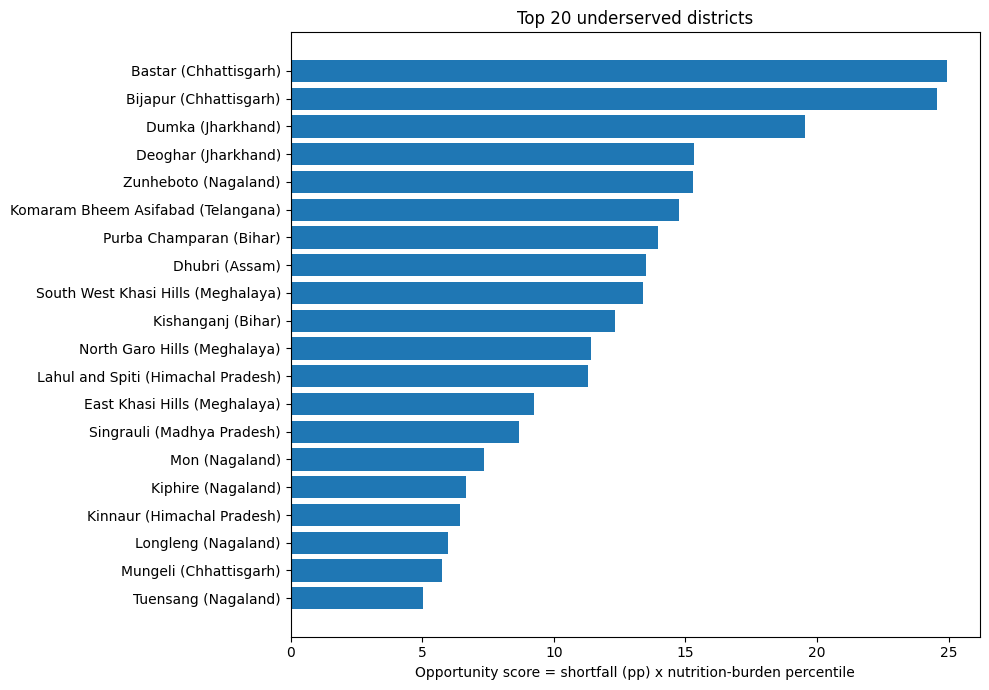


Eligible districts per state:
State
Nagaland             11
Chhattisgarh          3
Manipur               3
Meghalaya             3
Himachal Pradesh      2
Bihar                 2
Jharkhand             2
Assam                 1
Arunachal Pradesh     1
Madhya Pradesh        1
dtype: int64

Top 10 on the chronic-care lens (read with the screening caveat):


,State,District,inst_births,expected,gap,ncd_pct
434,Nagaland,Zunheboto,35.0,88.51,53.51,0.85
429,Nagaland,Mon,21.4,85.62,64.22,0.60
431,Nagaland,Phek,32.2,87.28,55.08,0.69
433,Nagaland,Wokha,43.6,88.46,44.86,0.81
427,Nagaland,Longleng,38.7,79.82,41.12,0.62
428,Nagaland,Mokokchung,51.5,93.55,42.05,0.45
430,Nagaland,Peren,43.5,79.73,36.23,0.44
426,Nagaland,Kohima,66.9,95.88,28.98,0.49
386,Manipur,Chandel,55.5,74.65,19.15,0.64
397,Meghalaya,North Garo Hills,61.5,80.33,18.83,0.63


In [34]:
# ---------- 9.3 Chart ----------
t = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(t['District'] + ' (' + t['State'] + ')', t['opp_score'])
ax.set_xlabel('Opportunity score = shortfall (pp) x nutrition-burden percentile')
ax.set_title('Top 20 underserved districts')
plt.tight_layout(); plt.show()

# ---------- 9.4 Where do they cluster? ----------
print("\nEligible districts per state:")
print(elig.groupby('State').size().sort_values(ascending=False).head(10))

# ---------- 9.5 Second lens: chronic-care (NCD) burden ----------
print("\nTop 10 on the chronic-care lens (read with the screening caveat):")
display(elig.nlargest(10, 'opp_score_ncd')[['State', 'District', TARGET_COL, 'expected', 'gap', 'ncd_pct']].round(2))

# ---------- Save ----------
df5.to_csv('district_opportunity_scores.csv', index=False)

**Observations (9.3)**
- Out-of-fold RMSE is 9.14 for all districts and 7.36 without Nagaland, so Nagaland alone adds almost two points of error. The 18.3-point cut-off is therefore conservative.
- **Nine of the top 20 survive the strict cut-off:** Bastar, Bijapur, Dumka, North Garo Hills and five Nagaland districts (Zunheboto, Mon, Kiphire, Longleng, Tuensang). The other eleven (for example Deoghar, Purba Champaran, Kishanganj, Dhubri, Singrauli) have gaps of 13.5-18.3 points. They are plausible but within the model's margin of error.
- **Bastar, Bijapur and Dumka are the core candidates:** large gaps (21.9-25.2 points), the highest burden percentiles (0.89-1.00), and they survive the strict test.
- A ranking by access gap alone is dominated by Nagaland: all ten top gaps are Nagaland districts (29-64 points). The two rankings answer different questions: "where is access worst?" and "where are access and need both bad?"
- Part of the Nagaland gap may be model error, since the state lies outside the training range (Step 8.3). Nagaland needs a separate, access-focused analysis.

In [35]:
# Code Reproducability
import numpy, pandas, matplotlib, scipy, sklearn
print(f"numpy=={numpy.__version__}\npandas=={pandas.__version__}\nmatplotlib=={matplotlib.__version__}\n"
      f"scipy=={scipy.__version__}\nscikit-learn=={sklearn.__version__}")

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scipy==1.16.3
scikit-learn==1.6.1


In [36]:
# 9.4 Robustness of the shortlist
oof_all = rmse_c(df5[TARGET_COL], df5['expected'])
nn = df5['State'] != 'Nagaland'
print(f"OOF RMSE, all districts: {oof_all:.2f} | without Nagaland: "
      f"{rmse_c(df5.loc[nn, TARGET_COL], df5.loc[nn, 'expected']):.2f}")

main = elig.nlargest(20, 'opp_score')
strict_cut = 2 * oof_all
robust = main[main['gap'] >= strict_cut]
print(f"\nStricter cut-off ({strict_cut:.1f} pp): {len(robust)} of the top 20 remain")
display(robust[['State', 'District', TARGET_COL, 'expected', 'gap', 'burden_pct', 'opp_score']].round(2))

print("\nPure access-gap ranking (ignores burden), top 10:")
display(elig.nlargest(10, 'gap')[['State', 'District', TARGET_COL, 'expected', 'gap']].round(1))

OOF RMSE, all districts: 9.14 | without Nagaland: 7.36

Stricter cut-off (18.3 pp): 9 of the top 20 remain


,State,District,inst_births,expected,gap,burden_pct,opp_score
111,Chhattisgarh,Bastar,63.5,88.65,25.15,0.99,24.94
113,Chhattisgarh,Bijapur,63.6,88.26,24.66,1.00,24.55
231,Jharkhand,Dumka,60.3,82.15,21.85,0.89,19.54
434,Nagaland,Zunheboto,35.0,88.51,53.51,0.29,15.29
397,Meghalaya,North Garo Hills,61.5,80.33,18.83,0.61,11.40
429,Nagaland,Mon,21.4,85.62,64.22,0.11,7.36
425,Nagaland,Kiphire,34.8,77.53,42.73,0.16,6.65
427,Nagaland,Longleng,38.7,79.82,41.12,0.15,5.99
432,Nagaland,Tuensang,34.8,75.31,40.51,0.12,5.04



Pure access-gap ranking (ignores burden), top 10:


,State,District,inst_births,expected,gap
429,Nagaland,Mon,21.4,85.6,64.2
431,Nagaland,Phek,32.2,87.3,55.1
434,Nagaland,Zunheboto,35.0,88.5,53.5
433,Nagaland,Wokha,43.6,88.5,44.9
425,Nagaland,Kiphire,34.8,77.5,42.7
428,Nagaland,Mokokchung,51.5,93.6,42.1
427,Nagaland,Longleng,38.7,79.8,41.1
432,Nagaland,Tuensang,34.8,75.3,40.5
430,Nagaland,Peren,43.5,79.7,36.2
426,Nagaland,Kohima,66.9,95.9,29.0


### 9.5 Digital readiness: which delivery model?
Telemedicine needs connectivity. District-level internet data are not in the district factsheets, so I use the NFHS-5 **state-level, rural** figure for women who have ever used the internet, compared with the national rural value (24.6%).

| Class | Rule | Suggested model |
|---|---|---|
| Pure telemedicine | state rural internet use at least 3 points above national | Remote consultation |
| Borderline | within 3 points of national | Test both |
| Assisted model | more than 3 points below national | Local health worker or kiosk with a remote doctor |

The 3-point band is my choice. It stops states that differ by a fraction of a point from falling into different classes.

**Caveats:** every district in a state gets the same value; it measures having ever used the internet, not network coverage or smartphone ownership; it covers women only; the data are from 2019-21.

In [37]:
![ -d nfhs5_states ] || git clone https://github.com/pratapvardhan/NFHS-5.git nfhs5_states
!ls nfhs5_states

import pandas as pd
st = pd.read_csv('nfhs5_states/NFHS-5-States.csv')
print(st.shape)
print(st.columns.tolist()[:12])

hit = st[st.apply(lambda r: r.astype(str).str.contains('internet|mobile', case=False).any(), axis=1)]
print(hit.shape)
display(hit.head(10))
print([c for c in st.columns if 'internet' in c.lower() or 'mobile' in c.lower()])

Cloning into 'nfhs5_states'...
remote: Enumerating objects: 149, done.
remote: Counting objects: 100% (149/149), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 149 (delta 114), reused 138 (delta 103), pack-reused 0 (from 0)
Receiving objects: 100% (149/149), 1.02 MiB | 4.41 MiB/s, done.
Resolving deltas: 100% (114/114), done.
district-level	NFHS-5-Districts.csv  README.md
LICENSE		NFHS-5-States.csv     status.csv
(4847, 7)
['state', 'state_code', 'indicator', 'nfhs5_urban', 'nfhs5_rural', 'nfhs5_total', 'nfhs4_total']
(111, 7)


,state,state_code,indicator,nfhs5_urban,nfhs5_rural,nfhs5_total,nfhs4_total
17,India,NaN,18. Women who have ever used the internet (%),51.8,24.6,33.3,NaN
18,India,NaN,19. Men who have ever used the internet (%),72.5,48.7,57.1,NaN
122,India,NaN,123. Women having a mobile phone that they themselves us...,69.4,46.6,54.0,45.9
148,Andaman & Nicobar Islands,AN,18. Women who have ever used the internet (%),44.1,27.9,34.8,NaN
149,Andaman & Nicobar Islands,AN,19. Men who have ever used the internet (%),54.6,41.1,46.5,NaN
253,Andaman & Nicobar Islands,AN,123. Women having a mobile phone that they themselves us...,80.8,80.9,80.8,66.9
279,Andhra Pradesh,AP,18. Women who have ever used the internet (%),33.9,15.4,21.0,NaN
280,Andhra Pradesh,AP,19. Men who have ever used the internet (%),65.1,41.5,48.8,NaN
384,Andhra Pradesh,AP,123. Women having a mobile phone that they themselves us...,67.4,40.9,48.9,36.2
410,Arunachal Pradesh,AR,18. Women who have ever used the internet (%),70.0,49.6,52.9,NaN


[]


In [38]:
# ---- 9.5 Telemedicine-readiness overlay (state-level connectivity) ----
st = pd.read_csv('nfhs5_states/NFHS-5-States.csv')
want = {'18.': 'net_w', '19.': 'net_m', '123.': 'mob_w'}
def tag(s):
    for k, v in want.items():
        if str(s).startswith(k + ' '):
            return v
    return None
st['var'] = st['indicator'].map(tag)
conn = st.dropna(subset=['var']).copy()
for c in ['nfhs5_urban', 'nfhs5_rural', 'nfhs5_total']:
    conn[c] = pd.to_numeric(conn[c], errors='coerce')

nat = conn[conn['state'] == 'India'].set_index('var')
bench = nat.loc['net_w', 'nfhs5_rural']
print(f"National benchmark - rural women internet use: {bench}% | rural women own mobile: {nat.loc['mob_w', 'nfhs5_rural']}%")

state = (conn[conn['state'] != 'India']
         .pivot_table(index='state', columns='var', values=['nfhs5_rural', 'nfhs5_total'], aggfunc='first'))
state.columns = [f"{v}_{c.replace('nfhs5_', '')}" for c, v in state.columns]
state = state.reset_index().rename(columns={'state': 'State'})

# ---- name matching ----
def norm(s):
    s = str(s).lower().replace('&', 'and').replace('nct of ', '').replace('nct ', '')
    s = re.sub(r'\bislands\b', 'island', s)
    s = re.sub(r'\s+', ' ', s).strip()
    if s.startswith('dadra') or s.startswith('daman'):
        s = 'dadra and nagar haveli and daman and diu'
    return s

state['key'] = state['State'].map(norm)
ov = df5.copy()
ov['key'] = ov['State'].map(norm)
ov = ov.merge(state.drop(columns='State'), on='key', how='left')

miss = ov.loc[ov['net_w_rural'].isna(), 'State'].unique()
print("District-file states with no connectivity match:", list(miss))
print("State-file names not used:", sorted(set(state['key']) - set(ov['key'])))

# ---- delivery-model class ----
def tele_class(x):
    if pd.isna(x):
        return 'no data'
    if x >= bench + 3:
        return 'pure telemedicine'
    if x >= bench - 3:
        return 'borderline'
    return 'assisted model'
ov['delivery_model'] = ov['net_w_rural'].map(tele_class)
ov['strict'] = ov['gap'] >= 2 * oof_all

# ---- shortlist with connectivity ----
short = ov[ov['gap'] >= GAP_MIN].nlargest(20, 'opp_score')
display(short[['State', 'District', TARGET_COL, 'expected', 'gap', 'opp_score', 'strict',
               'net_w_rural', 'mob_w_rural', 'delivery_model']].round(1))
print(short['delivery_model'].value_counts())
print("\nStrict-core districts by delivery model:")
print(short[short['strict']].groupby('delivery_model')['District'].apply(list))



National benchmark - rural women internet use: 24.6% | rural women own mobile: 46.6%
District-file states with no connectivity match: ['Chandigarh']
State-file names not used: []


,State,District,inst_births,expected,gap,opp_score,strict,net_w_rural,mob_w_rural,delivery_model
111,Chhattisgarh,Bastar,63.5,88.6,25.1,24.9,True,20.8,34.0,assisted model
113,Chhattisgarh,Bijapur,63.6,88.3,24.7,24.6,True,20.8,34.0,assisted model
231,Jharkhand,Dumka,60.3,82.2,21.9,19.5,True,22.7,43.7,borderline
229,Jharkhand,Deoghar,61.3,78.1,16.8,15.3,False,22.7,43.7,borderline
434,Nagaland,Zunheboto,35.0,88.5,53.5,15.3,True,40.3,76.3,pure telemedicine
570,Telangana,Komaram Bheem Asifabad,82.0,100.0,18.0,14.7,False,15.8,50.6,assisted model
95,Bihar,Purba Champaran,61.5,77.2,15.7,13.9,False,17.0,49.3,assisted model
45,Assam,Dhubri,64.2,78.5,14.3,13.5,False,24.4,53.9,borderline
401,Meghalaya,South West Khasi Hills,41.7,55.9,14.2,13.4,False,28.0,64.3,pure telemedicine
85,Bihar,Kishanganj,54.6,69.9,15.3,12.3,False,17.0,49.3,assisted model


delivery_model
pure telemedicine    10
assisted model        7
borderline            3
Name: count, dtype: int64

Strict-core districts by delivery model:
delivery_model
assisted model                                                 [Bastar, Bijapur]
borderline                                                               [Dumka]
pure telemedicine    [Zunheboto, North Garo Hills, Mon, Kiphire, Longleng, Tu...
Name: District, dtype: object


**Observations (9.5)**
- National benchmark: 24.6% of rural women have ever used the internet and 46.6% own a mobile phone they use themselves.
- Of the top 20: 10 are "pure telemedicine", 7 "assisted model" and 3 "borderline".
- **Strict-core districts by delivery model:**
  - Assisted model: Bastar and Bijapur (Chhattisgarh: rural internet use 20.8%, own mobile 34.0%).
  - Borderline: Dumka (Jharkhand: 22.7%, 43.7%).
  - Pure telemedicine: Zunheboto, Mon, Kiphire, Longleng, Tuensang (Nagaland: 40.3%, 76.3%) and North Garo Hills (Meghalaya: 28.0%, 64.3%).
- The assisted-model districts also include Purba Champaran and Kishanganj (Bihar 17.0%), Komaram Bheem Asifabad (Telangana 15.8%), Singrauli (Madhya Pradesh 20.1%) and Mungeli (Chhattisgarh).
- Low connectivity does not rule a district out. It changes the product: where internet use is low, a health-worker-assisted model is more realistic.
- A state average can hide hill districts with poor coverage, so Nagaland's "pure telemedicine" label must be verified locally.
- Chandigarh and NCT of Delhi were not matched to the state file; neither is in the shortlist, so the result is unaffected.

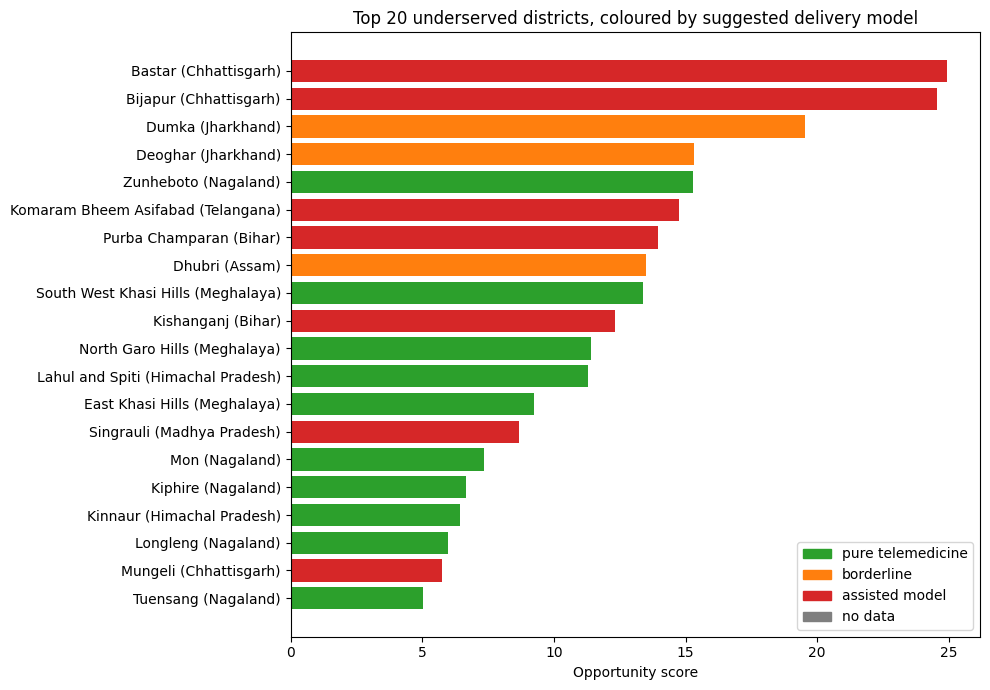

In [39]:
# ---- chart ----
colors = {'pure telemedicine': 'tab:green', 'borderline': 'tab:orange',
          'assisted model': 'tab:red', 'no data': 'tab:gray'}
t = short.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(t['District'] + ' (' + t['State'] + ')', t['opp_score'],
        color=[colors[m] for m in t['delivery_model']])
ax.set_xlabel('Opportunity score')
ax.set_title('Top 20 underserved districts, coloured by suggested delivery model')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colors.items()], loc='lower right')
plt.tight_layout()
plt.savefig('figures/fig5_top20_delivery_model.png', dpi=150, bbox_inches='tight')
plt.show()

ov.to_csv('district_opportunity_with_connectivity.csv', index=False)

### 9.5 Business reading of the results

| Tier | Districts | Suggested action |
|---|---|---|
| 1. Core pilots | Bastar, Bijapur (Chhattisgarh), Dumka (Jharkhand) | Large gap, high need, robust to a strict threshold. Pilot an assisted model with local health workers, because rural internet use is low |
| 2. Access-focused, to validate | Zunheboto, Mon, Kiphire, Longleng, Tuensang (Nagaland), North Garo Hills (Meghalaya) | Very large gaps and better state-level connectivity, but low measured burden and model uncertainty in Nagaland. Verify on the ground before committing |
| 3. Watch list | Deoghar, Purba Champaran, Kishanganj, Dhubri, Singrauli, Mungeli and the rest of the top 20 | Gaps within the model's error. Confirm with local data before acting |

The method says where to look first. It does not prove why access is low or how big the market is.

### 9.6 Limitations
- **Proxy outcome.** Institutional births stand in for access. There are no doctor or facility counts, so supply is not measured directly.
- **Survey error.** District values are survey estimates with sampling error, larger in small districts (for example Lahul and Spiti).
- **Association, not cause.** A large negative residual can reflect under-service or an unmeasured factor such as terrain or state policy.
- **Extrapolation.** Nagaland lies outside the range of the training states: test RMSE 44.8 for Nagaland against 7.34 for the other test states.
- **Small test set.** Eight states and 174 districts, so the test estimate is noisy; the split was fixed in advance and not changed.
- **Source-file fixes.** Three problems in the converted data were fixed by hand (Saraikela-Kharsawan mislabelled, Surajpur duplicates, Chandigarh and Lakshadweep values). These should be confirmed against the original PDFs.
- **Coverage.** 65 newer districts have no NFHS-4 data, so the temporal check covers 575 districts.
- **Screening effect.** Blood sugar and blood pressure appear to track screening and affluence, so they are poor measures of need here. This is a hypothesis, not tested.
- **Connectivity is coarse.** State-level, rural, women only, from 2019-21.
- **No market size.** No population or willingness-to-pay data.

### 9.7 Next steps
1. Merge Census population and HMIS facility counts to size demand and measure supply directly.
2. Add district-level connectivity (smartphone ownership, mobile-network coverage).
3. Quantify uncertainty with bootstrap intervals on the gaps.
4. Try gradient boosting and spatial cross-validation.
5. Validate the top districts with local health officials.

### 9.8 Conclusion
A state-grouped Ridge model predicts district institutional-birth rates from socioeconomic indicators with a validation RMSE of about 6.7 percentage points on unseen states, against 10.7 for the mean baseline. A Random Forest overfits (training RMSE 2.2 against validation 7.5), so the simpler model was kept. Comparing actual with expected access gives a shortlist of 33 districts with a large shortfall, and the strongest candidates for a first pilot are Bastar, Bijapur and Dumka, which also have high nutrition burden and survive a strict threshold. Rural internet use is low in the Chhattisgarh districts, so an assisted delivery model is more realistic there than pure telemedicine. The method shows where access gaps and need coincide. It does not establish their causes or the market size.

In [40]:
res.to_csv('model_comparison_cv.csv', index=False)
!zip -rq figures.zip figures

from google.colab import files
for f in ['figures.zip', 'district_opportunity_with_connectivity.csv', 'model_comparison_cv.csv']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>